# Máquinas Térmicas - Lección 14b (Bonus)
## El motor RAMJET completo: compresión por choques, llama anclada y empuje supersónico

**Fuentes estudiantiles (PUJ):**
- Santiago Cadavid Franco y Camilo Bayona Roa — *One-Dimensional Numerical Modelling of a Supersonic RAMJET Engine with Parametrizable Geometry* (manuscrito, `research_sources/RAMJET Engine/main.tex`). Incluye los códigos MATLAB `default_params.m`, `ramjet_geometry.m` y `ramjet_simulation_corregido.m`.
- A. Dallos Trujillo y C. A. Bayona Roa (2024) — *Integrated Thermodynamic Analysis of a Generic RAMJET*, tesis de pregrado: metano, Jet A-1, hidrógeno y octano entre Mach 2.2 y 4 (figura de validación de la entrega).

**Datos de validación:**
- NACA Report 1135 (*Equations, Tables and Charts for Compressible Flow*, 1953): ángulo del choque cónico.
- MIL-E-5007D: especificación de recuperación de presión total de tomas supersónicas.
- NACA RM E52L18a: recuperación medida en una toma de cono a Mach 2.
- Las tablas y figuras de la entrega y de la tesis de Dallos.

**Adaptación AVA:** Camilo Bayona

### Objetivos de aprendizaje
1. Explicar cómo un motor **sin turbomáquinas** comprime el aire: choques cónico y normal, y difusión subsónica.
2. Calcular el sistema de choques de un **cono** (Taylor–Maccoll) y la **característica de la toma** (recuperación contra caudal).
3. Acoplar la toma con la **garganta sónica** de la tobera y reconocer los regímenes supercrítico, crítico, subcrítico y de **zumbido**.
4. Resolver el flujo **cuasi-1D** en la cámara (EDO en $x$ con calor y fricción) y el **estrangulamiento térmico** (Rayleigh).
5. Usar **cinética química** (reactor agitado en el tiempo, llama laminar) para decidir si la llama se sostiene y cuánto combustible alcanza a quemarse.
6. Simular en el tiempo el **zumbido** de la toma y la **trayectoria** de un vehículo propulsado.

> **Qué es de quién.** Los recuadros 🎓 son contribución de los estudiantes. El resto es teoría estándar (Anderson, Shapiro, Mattingly, Greitzer) o desarrollo de esta adaptación. Cada supuesto propio se marca como **SUPUESTO**.

In [1]:
# Instalación solo en Google Colab; en el entorno local del curso es un no-op
import sys, os, subprocess, urllib.request
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cantera==3.2.0", "CoolProp", "ipywidgets"], check=True)
    from google.colab import output
    output.enable_custom_widget_manager()
os.makedirs("data", exist_ok=True)
REPO = "https://raw.githubusercontent.com/camilobayonaroa/ThermalMachines/"
for arch in ("ramjet_cinetica.json", "ramjet_resultados.json", "nheptane_lu88sk.yaml", "isooctane_yoo2013.yaml"):
    ruta = os.path.join("data", arch)
    for rama in ("main", "nb14b-motor-ramjet"):
        if os.path.exists(ruta): break
        try: urllib.request.urlretrieve(REPO + rama + "/notebooks/data/" + arch, ruta)
        except Exception: pass
    print(arch, "disponible:", os.path.exists(ruta))

ramjet_cinetica.json disponible: True
ramjet_resultados.json disponible: True
nheptane_lu88sk.yaml disponible: True
isooctane_yoo2013.yaml disponible: True


In [2]:
# === Setup ===================================================================
import warnings
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Circle, Wedge
import pandas as pd
import CoolProp.CoolProp as CP
from ipywidgets import (interactive_output, FloatSlider, IntSlider, Dropdown, ToggleButtons, HBox, VBox, Button,
                        Output, HTML)
from IPython.display import display
warnings.filterwarnings("ignore")
COL = {"tinta": "#3a3a38", "gris": "#8a8a86", "aire": "#2a78d6", "choque": "#4a3aa7", "gas": "#e34948",
       "tibio": "#eb6834", "verde": "#1baf7a", "metal": "#c3c2b7", "aviso": "#e34948"}
COLC = {"Hidrógeno": "#e2a000", "Metano": "#2a78d6", "Jet A-1 (n-heptano)": "#e34948", "Octano (iso-octano)": "#4a3aa7"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

In [3]:
# === Dinámica de gases: isentrópico, choques normal y oblicuo, Taylor-Maccoll, flujo cuasi-1D generalizado ===
import math, json, os, time
import numpy as np
from scipy.optimize import brentq
from scipy.integrate import solve_ivp
import cantera as ct
ct.suppress_thermo_warnings()

G0 = 9.80665
R_AIRE = 287.05

def isen(M, g=1.4):
    a = 1 + 0.5*(g - 1)*M**2
    return dict(T=1/a, p=a**(-g/(g - 1)), rho=a**(-1/(g - 1)))

def area_mach(M, g=1.4):
    return (1/M)*((2/(g + 1))*(1 + 0.5*(g - 1)*M**2))**((g + 1)/(2*(g - 1)))

def mach_area(Ar, rama="sub", g=1.4):
    Ar = max(Ar, 1.0 + 1e-12)
    if rama == "sub":
        return brentq(lambda M: area_mach(M, g) - Ar, 1e-6, 1.0)
    return brentq(lambda M: area_mach(M, g) - Ar, 1.0, 50.0)

def flujo_masico_param(M, g=1.4, R=R_AIRE):
    # mdot*sqrt(T0)/(p0*A)
    return math.sqrt(g/R)*M*(1 + 0.5*(g - 1)*M**2)**(-(g + 1)/(2*(g - 1)))

def choque_normal(M1, g=1.4):
    M2 = math.sqrt((1 + 0.5*(g - 1)*M1**2)/(g*M1**2 - 0.5*(g - 1)))
    p21 = 1 + 2*g/(g + 1)*(M1**2 - 1)
    T21 = p21*(2 + (g - 1)*M1**2)/((g + 1)*M1**2)
    p0r = ((g + 1)*M1**2/((g - 1)*M1**2 + 2))**(g/(g - 1))*((g + 1)/(2*g*M1**2 - (g - 1)))**(1/(g - 1))
    return dict(M2=M2, p21=p21, T21=T21, p0r=p0r)

def theta_beta(M, beta, g=1.4):
    return math.atan(2/math.tan(beta)*(M**2*math.sin(beta)**2 - 1)/(M**2*(g + math.cos(2*beta)) + 2))

def choque_oblicuo(M, theta, g=1.4):
    # solucion debil
    mu = math.asin(1/M)
    bs = np.linspace(mu + 1e-6, math.pi/2 - 1e-6, 2000)
    th = np.array([theta_beta(M, b, g) for b in bs])
    k = int(np.argmax(th))
    if theta > th[k]:
        return None          # choque desprendido
    beta = brentq(lambda b: theta_beta(M, b, g) - theta, bs[0], bs[k])
    n = choque_normal(M*math.sin(beta), g)
    return dict(beta=beta, M2=n["M2"]/math.sin(beta - theta), p21=n["p21"], T21=n["T21"], p0r=n["p0r"],
                theta_max=th[k])

def taylor_maccoll(M, cono, g=1.4):
    """Flujo conico supersonico (Taylor-Maccoll): dado el semiangulo del cono, angulo del choque por disparo.
    Devuelve angulo de choque, Mach en la superficie del cono y relacion de presion total."""
    def resolver(beta):
        if M*math.sin(beta) <= 1.0:
            return None
        n = choque_normal(M*math.sin(beta), g)
        delta = theta_beta(M, beta, g)
        M2 = n["M2"]/math.sin(beta - delta)
        V = (2/((g - 1)*M2**2) + 1)**-0.5              # V/Vmax
        Vr, Vt = V*math.cos(beta - delta), -V*math.sin(beta - delta)
        def f(th, y):
            vr, vt = y
            B = 0.5*(g - 1)*(1 - vr**2 - vt**2)
            return [vt, (vt**2*vr - B*(2*vr + vt/math.tan(th)))/(B - vt**2)]
        ev = lambda th, y: y[1]
        ev.terminal = True; ev.direction = 1
        s = solve_ivp(f, [beta, 1e-3], [Vr, Vt], events=ev, rtol=1e-10, atol=1e-12, max_step=1e-3)
        if not s.t_events[0].size:
            return None
        thc = s.t_events[0][0]; vr = s.y_events[0][0][0]
        Mc = math.sqrt(2/((g - 1)*(1/vr**2 - 1)))
        return dict(beta=beta, cono=thc, Mc=Mc, p0r=n["p0r"], delta=delta, M2=M2)
    mu = math.asin(1/M)
    bs = np.linspace(mu + 1e-4, math.radians(89), 300)
    prev = None
    for b in bs:
        r = resolver(b)
        if r is None:
            continue
        if r["cono"] >= cono:
            lo = prev if prev is not None else mu + 1e-5
            beta = brentq(lambda bb: (resolver(bb) or {"cono": 0})["cono"] - cono, lo, b, xtol=1e-10)
            return resolver(beta)
        prev = b
    return None      # choque desprendido

# --- Flujo cuasi-1D generalizado (coeficientes de influencia de Shapiro) ---
def dM2_dx(M2, g, dlnA, dlnT0, fric4D, dlnm):
    """dM^2/dx con cambio de area, adicion de calor (T0), friccion 4cf/D y adicion de masa."""
    psi = 1 + 0.5*(g - 1)*M2
    return M2*psi/(1 - M2)*(-2*dlnA + (1 + g*M2)*dlnT0 + g*M2*fric4D + 2*(1 + g*M2)*dlnm)

def dlnp0_dx(M2, g, dlnT0, fric4D):
    return -0.5*g*M2*(dlnT0 + fric4D)

def rayleigh_T0(M, g=1.4):
    return (g + 1)*M**2*(2 + (g - 1)*M**2)/(1 + g*M**2)**2

def fanno_4fL(M, g=1.4):
    return (1 - M**2)/(g*M**2) + (g + 1)/(2*g)*math.log((g + 1)*M**2/(2 + (g - 1)*M**2))

In [4]:
def isa(h, dT=0.0):
    if h <= 11000.0:
        T = 288.15 - 0.0065*h; p = 101325.0*(T/288.15)**5.25588
    else:
        T = 216.65; p = 22632.06*math.exp(-G0*(h - 11000.0)/(R_AIRE*216.65))
    T += dT
    return T, p, p/(R_AIRE*T)

## 1. Contexto: cinco ideas que explican un ramjet

1. **El aire se comprime solo con la velocidad.** A Mach 2 la presión total del aire es 7.8 veces la estática. Si se desacelera sin pérdidas hasta casi detenerlo, se obtiene esa compresión sin compresor ni turbina. Es el mismo ciclo Brayton de las Lecciones 13–14, pero el compresor es la geometría.
2. **Desacelerar un flujo supersónico exige choques, y los choques destruyen presión total.** Un solo choque normal a Mach 2 pierde el 28 %. Un **cono** reparte la compresión en un choque oblicuo débil más uno normal más débil, y recupera más del 90 %.
3. **La garganta de la tobera fija el caudal.** Con la garganta sónica, $\dot m\propto p_{04}A_5/\sqrt{T_{04}}$. Si la llama calienta más, la tobera pasa menos aire a la misma presión, y la toma tiene que adaptarse moviendo su choque.
4. **La combustión es subsónica y está limitada por la química.** A Mach 0.2 el aire de la cámara tiene 400 K y la mezcla no se autoenciende en los milisegundos que pasa allí. Un **estabilizador de llama** crea una zona de recirculación (un reactor agitado) que la mantiene viva, y desde él se propaga un frente turbulento.
5. **Un ramjet no arranca solo.** A baja velocidad no hay compresión ni caudal. Necesita un acelerador hasta Mach ≈ 1.8–2, y a partir de ahí su empuje crece con la velocidad.

## 2. El motor y sus estaciones

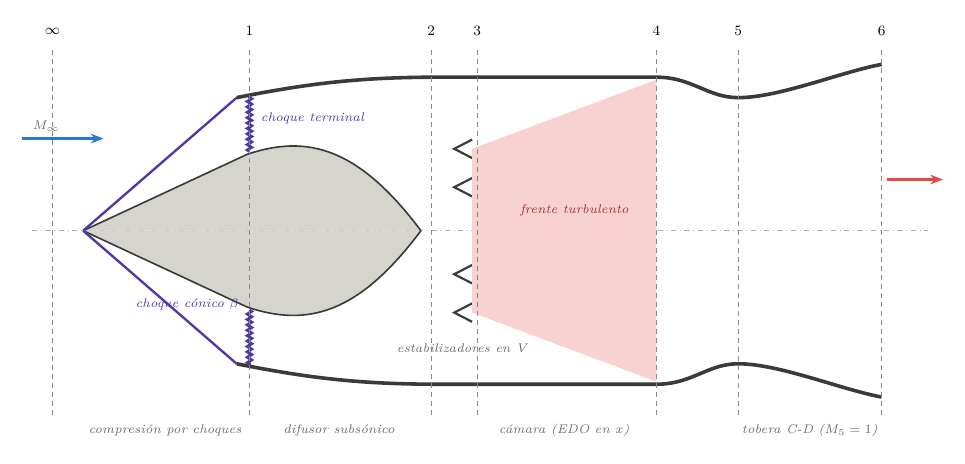

*Figura 1 (TikZ, `docs/figures/tikz/rj_estaciones.tex`).* Del aire libre (∞) a la superficie del cono (1), el choque terminal y el difusor subsónico (2), la entrada a la cámara tras los estabilizadores (3), la salida de la cámara (4), la garganta (5) y la salida de la tobera (6).

> 🎓 **La geometría de la entrega.** La entrega construye la geometría con splines de Hermite $C^1$. Así el área $A(x)$ y su derivada son continuas y la ecuación área–velocidad no oscila. Al reproducir su tabla de resultados aparecen dos hallazgos:
> 1. La tabla corresponde a una garganta de 139.7 mm; el código actual usa 92 mm.
> 2. El labio dibujado ($r\approx31$ mm) capta solo una fracción del aire que esa garganta pide (2.79 kg/s exigen $r\approx60$ mm). La entrega no verifica esta compatibilidad, porque toma el caudal de la garganta y no de la toma.

In [7]:
# === Réplica de la entrega: estaciones y métricas (ramjet_simulation_corregido.m) y su geometría Hermite ===
def entrega_ramjet(rcd=0.0699, sigma_b=0.98, rc=0.090, re_exit=0.092, M_inf=2.0, T_inf=223.15, P_inf=26500.0,
                   f=0.030, eta_d=0.92, eta_b=0.98, LHV=43.0e6, g=1.4, R=287.05):
    """Replica de ramjet_simulation_corregido.m (estaciones y metricas globales) con los datos de la Tabla 1."""
    Cp = g*R/(g - 1)
    ua = M_inf*math.sqrt(g*R*T_inf)
    T0 = T_inf*(1 + 0.5*(g - 1)*M_inf**2); P0 = P_inf*(1 + 0.5*(g - 1)*M_inf**2)**(g/(g - 1))
    P02 = eta_d*P0; T02 = T0
    T04 = T02 + f*eta_b*LHV/((1 + f)*Cp); P04 = sigma_b*P02
    A5 = math.pi*rcd**2; A6 = math.pi*re_exit**2; A3 = math.pi*rc**2
    mg = P04*A5/math.sqrt(T04)*flujo_masico_param(1.0, g, R); ma = mg/(1 + f); mf = f*ma
    M3 = mach_area(A3/(ma*math.sqrt(T02)/(P02*flujo_masico_param(1.0, g, R))), "sub", g)
    M4 = mach_area(A3/A5, "sub", g)
    M6 = mach_area(A6/A5, "sup", g)
    T6 = T04*isen(M6, g)["T"]; P6 = P04*isen(M6, g)["p"]; u6 = M6*math.sqrt(g*R*T6)
    Fg = mg*u6 + (P6 - P_inf)*A6; Fn = Fg - ma*ua
    Q = mf*LHV*eta_b
    return dict(ma=ma, mf=mf, mg=mg, M3=M3, M4=M4, M6=M6, T6=T6, P6=P6, u6=u6, T04=T04, P04=P04, P02=P02,
                Fg=Fg, Fn=Fn, Isp=Fn/(mf*G0), eta_th=0.5*(mg*u6**2 - ma*ua**2)/Q, eta_p=2*ua/(u6 + ua),
                A_captura=ma/(P_inf/(R*T_inf)*ua), ua=ua)

def hermite(x, x0, y0, m0, x1, y1, m1):
    L = x1 - x0; t = (x - x0)/L
    return (2*t**3 - 3*t**2 + 1)*y0 + (t**3 - 2*t**2 + t)*L*m0 + (-2*t**3 + 3*t**2)*y1 + (t**3 - t**2)*L*m1

def geometria_entrega(N=1500):
    """Geometria de default_params.m / ramjet_geometry.m de la entrega (Hermite C1)."""
    p = dict(l1=0.20, l2=0.22, l3=0.32, l4=0.38, l5=0.14, l6=0.24, rc=0.090, rcd=0.0699, re_exit=0.092,
             xlip_frac=0.22, g_lip=0.024, r_inlet=0.096, ri_x1=0.004, ri_peak=0.058, xm_frac=0.42)
    x1 = p["l1"]; x2 = x1 + p["l2"]; x3 = x2 + p["l3"]; x4 = x3 + p["l4"]; x5 = x4 + p["l5"]; x6 = x5 + p["l6"]
    xlip = x1 + p["xlip_frac"]*p["l2"]; xm = x2 + p["xm_frac"]*p["l3"]; x3e = x3 - 0.07*p["l3"]
    x = np.linspace(0, x6, N)
    ri = np.where((x >= x1) & (x <= xm), hermite(x, x1, p["ri_x1"], 0, xm, p["ri_peak"], 0), 0.0)
    ri = np.where((x > xm) & (x <= x3e), hermite(x, xm, p["ri_peak"], 0, x3e, 0, 0), ri)
    ri_lip = float(hermite(xlip, x1, p["ri_x1"], 0, xm, p["ri_peak"], 0))
    r_lip = min(ri_lip + p["g_lip"], 0.87*p["r_inlet"])
    re = np.full_like(x, np.nan)
    k = (x >= xlip) & (x <= x2); re[k] = hermite(x[k], xlip, r_lip, (p["r_inlet"] - r_lip)/(x2 - xlip), x2, p["r_inlet"], 0)
    ri2 = float(hermite(x2, x1, p["ri_x1"], 0, xm, p["ri_peak"], 0))
    A2, A3, A5, A6 = math.pi*(p["r_inlet"]**2 - ri2**2), math.pi*p["rc"]**2, math.pi*p["rcd"]**2, math.pi*p["re_exit"]**2
    A = np.full_like(x, np.nan)
    for (xa, xb, Aa, Ab) in [(x2, x3, A2, A3), (x4, x5, A3, A5), (x5, x6, A5, A6)]:
        k = (x >= xa) & (x <= xb); A[k] = hermite(x[k], xa, Aa, 0, xb, Ab, 0)
    A[(x > x3) & (x < x4)] = A3
    k = ~np.isnan(A); re[k] = np.sqrt(A[k]/math.pi + ri[k]**2)
    return dict(x=x, ri=ri, re=re, A=A, st=dict(x0=0, x1=x1, x2=x2, x3=x3, x4=x4, x5=x5, x6=x6, xlip=xlip),
                r_lip=r_lip, ri_lip=ri_lip, A_captura=math.pi*r_lip**2, p=p)

,magnitud,entrega (Tabla),réplica,error [%]
0,Fn,1719.4000,1722.2624,0.1665
1,Isp,2094.6000,2094.7863,0.0089
2,M6,2.0330,2.0313,-0.0860
3,T6,888.7000,889.4043,0.0793
4,ma,2.7900,2.7946,0.1644
5,mf,0.0837,0.0838,0.1644
6,eta_th,0.4590,0.4589,-0.0237
7,eta_p,0.6600,0.6606,0.0889


Captura necesaria para 2.79 kg/s a Mach 2, 10 km: 0.0113 m² (r = 59.9 mm)
Captura del labio dibujado (r_lab = 30.7 mm): 0.0030 m² -> 26 % de lo necesario
Con la garganta del código actual (92 mm, sigma_b 0.95): ma = 1.17 kg/s, F_N = 473 N


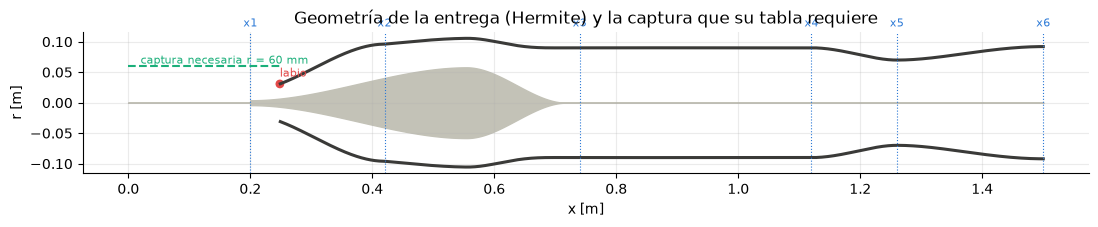

In [8]:
ref = dict(Fn=1719.4, Isp=2094.6, M6=2.033, T6=888.7, ma=2.790, mf=0.0837, eta_th=0.459, eta_p=0.660)
r = entrega_ramjet()
V2 = pd.DataFrame([(k, ref[k], r[k], 100*(r[k]/ref[k] - 1)) for k in ref], columns=["magnitud", "entrega (Tabla)", "réplica", "error [%]"])
display(V2.round(4))
ge = geometria_entrega()
print("Captura necesaria para %.2f kg/s a Mach 2, 10 km: %.4f m² (r = %.1f mm)" % (r["ma"], r["A_captura"], 1e3*math.sqrt(r["A_captura"]/math.pi)))
print("Captura del labio dibujado (r_lab = %.1f mm): %.4f m² -> %.0f %% de lo necesario" % (1e3*ge["r_lip"], ge["A_captura"], 100*ge["A_captura"]/r["A_captura"]))
r92 = entrega_ramjet(rcd=0.046, sigma_b=0.95)
print("Con la garganta del código actual (92 mm, sigma_b 0.95): ma = %.2f kg/s, F_N = %.0f N" % (r92["ma"], r92["Fn"]))
fig, ax = plt.subplots(figsize=(11, 3.3))
for sg in (1, -1):
    ax.plot(ge["x"], sg*ge["re"], color=COL["tinta"], lw=2.2)
    ax.fill_between(ge["x"], sg*ge["ri"], 0, color=COL["metal"])
st = ge["st"]
for k in ("x1", "x2", "x3", "x4", "x5", "x6"):
    ax.axvline(st[k], color=COL["aire"], ls=":", lw=0.8); ax.text(st[k], 0.125, k, color=COL["aire"], ha="center", fontsize=8)
ax.add_patch(Circle((st["xlip"], ge["r_lip"]), 0.006, color=COL["aviso"])); ax.text(st["xlip"], ge["r_lip"] + 0.012, "labio", color=COL["aviso"], fontsize=8)
ax.plot([0, st["xlip"]], [0.060, 0.060], "--", color=COL["verde"]); ax.text(0.02, 0.064, "captura necesaria r = 60 mm", color=COL["verde"], fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("r [m]"); ax.set_title("Geometría de la entrega (Hermite) y la captura que su tabla requiere")
plt.tight_layout(); plt.show()

## 3. Compresión por choques: el cono

Un cuerpo cónico en flujo supersónico genera un **choque cónico**. A diferencia de la cuña 2D, detrás de él el flujo sigue comprimiéndose de forma isentrópica hasta la superficie. Las ecuaciones de Taylor–Maccoll describen ese flujo, con velocidades adimensionales $V_r, V_\theta$ que dependen solo del ángulo $\theta$:

$$\frac{dV_r}{d\theta}=V_\theta,\qquad \frac{dV_\theta}{d\theta}=\frac{V_\theta^2V_r-\tfrac{\gamma-1}{2}\left(1-V_r^2-V_\theta^2\right)\left(2V_r+V_\theta\cot\theta\right)}{\tfrac{\gamma-1}{2}\left(1-V_r^2-V_\theta^2\right)-V_\theta^2}$$

Se integra desde el choque (Rankine–Hugoniot) hasta el ángulo en que $V_\theta=0$, que es la superficie del cono. Por **disparo** sobre el ángulo del choque $\beta$ se encuentra el que corresponde a un cono dado. Las pérdidas de presión total son solo las del choque:

$$\frac{p_{02}}{p_{01}}=\left[\frac{(\gamma+1)M_n^2}{(\gamma-1)M_n^2+2}\right]^{\frac{\gamma}{\gamma-1}}\left[\frac{\gamma+1}{2\gamma M_n^2-(\gamma-1)}\right]^{\frac{1}{\gamma-1}},\qquad M_n=M_\infty\sin\beta$$

**V1. Taylor–Maccoll contra NACA 1135.** Las cartas del NACA Report 1135 dan, a Mach 2, choques de 31.2° para un cono de 10° y de 37.8° para uno de 20°.

In [10]:
V1 = []
for Mi, c, ref_beta in [(2.0, 10.0, 31.2), (2.0, 20.0, 37.8)]:
    tm = taylor_maccoll(Mi, math.radians(c))
    V1.append((Mi, c, ref_beta, math.degrees(tm["beta"]), 100*(math.degrees(tm["beta"])/ref_beta - 1), tm["Mc"]))
display(pd.DataFrame(V1, columns=["M∞", "cono [°]", "β NACA 1135 [°]", "β Taylor-Maccoll [°]", "error [%]", "Mach en la superficie"]).round(3))

,M∞,cono [°],β NACA 1135 [°],β Taylor-Maccoll [°],error [%],Mach en la superficie
0,2.0,10.0,31.2,31.206,0.020,1.834
1,2.0,20.0,37.8,37.796,-0.011,1.568


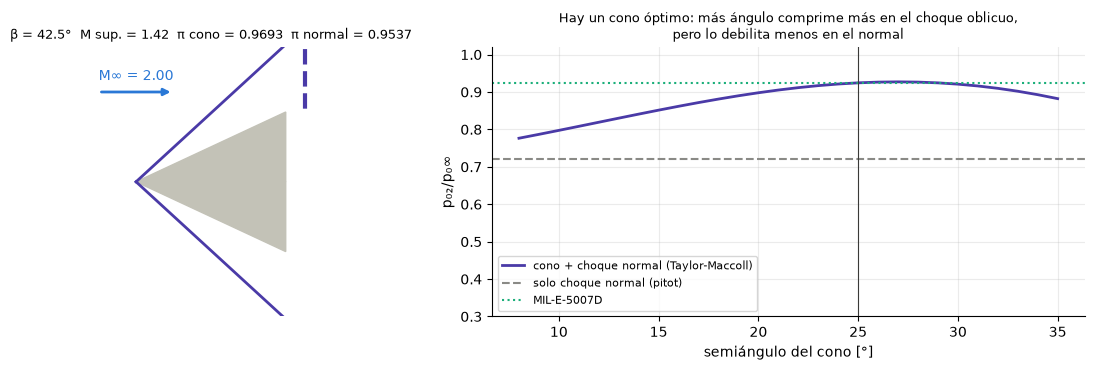

In [11]:
def widget_choques(Minf=2.0, cono=25.0):
    conos = np.arange(8, 36, 1.0); rec_c, rec_n = [], []
    for c in conos:
        tm = taylor_maccoll(Minf, math.radians(c))
        rec_c.append(tm["p0r"]*choque_normal(tm["Mc"])["p0r"] if tm else np.nan)
    tm = taylor_maccoll(Minf, math.radians(cono))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
    if tm is None:
        a1.text(0.5, 0.5, "choque desprendido:\nel cono es demasiado romo para este Mach", ha="center", transform=a1.transAxes, color=COL["aviso"])
        a1.axis("off")
    else:
        L = 1.0; b = tm["beta"]; c = math.radians(cono)
        for sg in (1, -1):
            a1.fill([0, L, L], [0, sg*L*math.tan(c), 0], color=COL["metal"])
            a1.plot([0, L*1.15], [0, sg*L*1.15*math.tan(b)], color=COL["choque"], lw=2)
        a1.plot([L*1.15*0.98, L*1.15*0.98], [L*1.15*math.tan(b)*0.98, L*math.tan(c)], color=COL["choque"], lw=3, ls="--")
        a1.annotate("", xy=(0.25, 0.6), xytext=(-0.25, 0.6), arrowprops=dict(arrowstyle="-|>", color=COL["aire"], lw=2))
        a1.text(-0.25, 0.68, "M∞ = %.2f" % Minf, color=COL["aire"])
        a1.set_aspect("equal"); a1.set_xlim(-0.3, 1.3); a1.set_ylim(-0.9, 0.9); a1.axis("off")
        a1.set_title("β = %.1f°  M sup. = %.2f  π cono = %.4f  π normal = %.4f" % (math.degrees(b), tm["Mc"], tm["p0r"], choque_normal(tm["Mc"])["p0r"]), fontsize=9)
    a2.plot(conos, rec_c, color=COL["choque"], lw=2, label="cono + choque normal (Taylor-Maccoll)")
    a2.axhline(choque_normal(Minf)["p0r"], color=COL["gris"], ls="--", label="solo choque normal (pitot)")
    a2.axhline(1 - 0.075*(Minf - 1)**1.35, color=COL["verde"], ls=":", label="MIL-E-5007D")
    a2.axvline(cono, color=COL["tinta"], lw=0.8)
    a2.set_xlabel("semiángulo del cono [°]"); a2.set_ylabel("p₀₂/p₀∞"); a2.set_ylim(0.3, 1.02); a2.legend(fontsize=8)
    a2.set_title("Hay un cono óptimo: más ángulo comprime más en el choque oblicuo,\npero lo debilita menos en el normal", fontsize=9)
    plt.tight_layout(); plt.show()
w1 = dict(Minf=FloatSlider(value=2.0, min=1.5, max=3.5, step=0.1, description="M∞", continuous_update=False),
          cono=FloatSlider(value=25, min=8, max=35, step=1, description="cono [°]", continuous_update=False))
display(VBox([HBox(list(w1.values())), interactive_output(widget_choques, w1)]))

## 4. La toma y su acople con la tobera

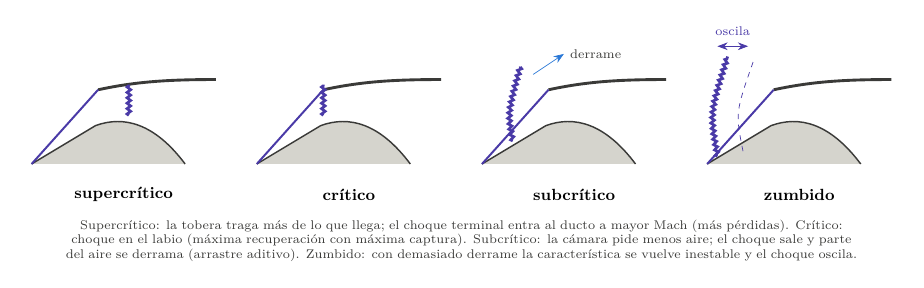

**Diseño corregido.** Se conserva lo que la entrega definió bien: la cámara de Ø180 mm y 0.38 m, el difusor de 0.32 m y la idea de spike. A eso se agrega:
- cono de 25°, cerca del óptimo a Mach 2 (Widget 1);
- labio de 60 mm, que capta el caudal de la tabla de la entrega;
- choque sobre el labio a Mach 2.

La garganta se dimensiona para que la toma quede justo **subcrítica** con φ = 0.6, y la salida para expansión adaptada a 10 km.

**El acople.** El caudal que la toma puede entregar y el que la tobera puede tragar deben coincidir:

$$\underbrace{\dot m_a\,(1+f)}_{\text{toma}}=\underbrace{A_5\,\max_p\!\left(\rho u\right)_{s_{04},h_{04}}}_{\text{garganta sónica}}$$

La incógnita $z$ es la posición del choque terminal ($z>0$: dentro del ducto, a un Mach mayor) o el derrame ($z<0$: caudal menor que la captura). En el código, la función `punto()` resuelve este equilibrio con `brentq` sobre $z$.

In [13]:
# === Toma externa: cono + choque terminal; difusor subsónico con fricción (EDO en x) ===
def toma_externa(Minf, cono, M_dis, r_lab):
    """Cono + choque terminal. Recuperacion de presion total del cono, Mach en la superficie y captura relativa."""
    tm = taylor_maccoll(Minf, math.radians(cono))
    tmd = taylor_maccoll(M_dis, math.radians(cono))
    x_lab = r_lab/math.tan(tmd["beta"])                 # labio sobre el choque al Mach de diseno
    if tm is None:                                        # choque desprendido: normal delante del labio
        n = choque_normal(Minf)
        return dict(desprendido=True, beta=math.pi/2, Mc=n["M2"], p0_cono=n["p0r"], A0Ac=0.6, x_lab=x_lab,
                    p_s=n["p21"], delta_s=0.0)
    if tm["beta"] >= tmd["beta"]:                          # choque por fuera del labio: derrame
        tb, td = math.tan(tm["beta"]), math.tan(tm["delta"])
        r0 = (r_lab - x_lab*td)/(1 - td/tb)
        A0Ac = (r0/r_lab)**2
    else:
        A0Ac = 1.0
    ob = choque_oblicuo(Minf, tm["delta"])
    return dict(desprendido=False, beta=tm["beta"], Mc=tm["Mc"], p0_cono=tm["p0r"], A0Ac=A0Ac, x_lab=x_lab,
                p_s=ob["p21"] if ob else 1.0, delta_s=tm["delta"])

def difusor_subsonico(M_in, A_in, A_out, L, D_h, cf, g=1.4):
    """Difusor subsonico (area en coseno) con friccion: integra la EDO cuasi-1D en x."""
    def A(x): return A_in + (A_out - A_in)*0.5*(1 - math.cos(math.pi*x/L))
    def dA(x): return (A_out - A_in)*0.5*math.pi/L*math.sin(math.pi*x/L)
    def f(x, y):
        M2, lnp0 = y
        Dh = math.sqrt(4*A(x)/math.pi)
        return [dM2_dx(M2, g, dA(x)/A(x), 0.0, 4*cf/Dh, 0.0), dlnp0_dx(M2, g, 0.0, 4*cf/Dh)]
    s = solve_ivp(f, [0, L], [M_in**2, 0.0], rtol=1e-8, atol=1e-10)
    return math.sqrt(s.y[0, -1]), math.exp(s.y[1, -1])

## 5. Flujo cuasi-unidimensional generalizado: área, calor y fricción

🎓 La entrega integra la relación área–velocidad $\frac{du}{dx}=\frac{u}{M^2-1}\frac{1}{A}\frac{dA}{dx}$. Aquí se generaliza con los **coeficientes de influencia de Shapiro**, para que en la misma EDO actúen el área, la adición de calor (cambio de $T_0$), la fricción y la adición de masa:

$$\frac{dM^2}{dx}=\frac{M^2\left(1+\frac{\gamma-1}{2}M^2\right)}{1-M^2}\left[-2\frac{d\ln A}{dx}+\left(1+\gamma M^2\right)\frac{d\ln T_0}{dx}+\gamma M^2\frac{4c_f}{D}+2\left(1+\gamma M^2\right)\frac{d\ln\dot m}{dx}\right]$$

$$\frac{d\ln p_0}{dx}=-\frac{\gamma M^2}{2}\left(\frac{d\ln T_0}{dx}+\frac{4c_f}{D}\right)$$

El denominador $1-M^2$ es la clave del ramjet. Calentar un flujo **subsónico** lo acelera hacia $M=1$, y no se puede agregar más calor que el que lleva a $M=1$ (**estrangulamiento térmico**, flujo de Rayleigh). Además, calentar a Mach alto cuesta presión total. Por eso la cámara trabaja a $M\approx0.15$–$0.2$.

**Verificación contra las soluciones analíticas.** Rayleigh: calentar a área constante hasta $T_0^*$ debe llevar $M\to1$. Fanno: la longitud de fricción que lleva a $M\to1$ es $4c_fL^*/D$.

In [15]:
g = 1.4; M0 = 0.2
T0s = 1/rayleigh_T0(M0)
s = solve_ivp(lambda x, y: [dM2_dx(y[0], g, 0, (T0s*0.9999 - 1)/y[1], 0, 0), T0s*0.9999 - 1], [0, 1], [M0**2, 1.0], rtol=1e-11, atol=1e-13)
M_fin = math.sqrt(s.y[0, -1]); M_ana = brentq(lambda M: rayleigh_T0(M) - rayleigh_T0(M0)*T0s*0.9999, 0.5, 1.0)
M0f = 0.3; L4 = fanno_4fL(M0f)*0.8
s2 = solve_ivp(lambda x, y: [dM2_dx(y[0], g, 0, 0, 1.0, 0)], [0, L4], [M0f**2], rtol=1e-12, atol=1e-14)
Mf = math.sqrt(s2.y[0, -1])
VER_1D = pd.DataFrame([("Rayleigh: M tras calentar a 0.9999 T0*", M_fin, M_ana, 100*(M_fin/M_ana - 1)),
                       ("Fanno: 4cfL*/D restante tras 80 %", fanno_4fL(Mf), 0.2*fanno_4fL(M0f), 100*(fanno_4fL(Mf)/(0.2*fanno_4fL(M0f)) - 1))],
                      columns=["verificación", "EDO", "analítica", "error [%]"])
display(VER_1D.round(6))

,verificación,EDO,analítica,error [%]
0,Rayleigh: M tras calentar a 0.9999 T0*,0.988095,0.988095,-0.0
1,Fanno: 4cfL*/D restante tras 80 %,1.059851,1.059851,-0.0


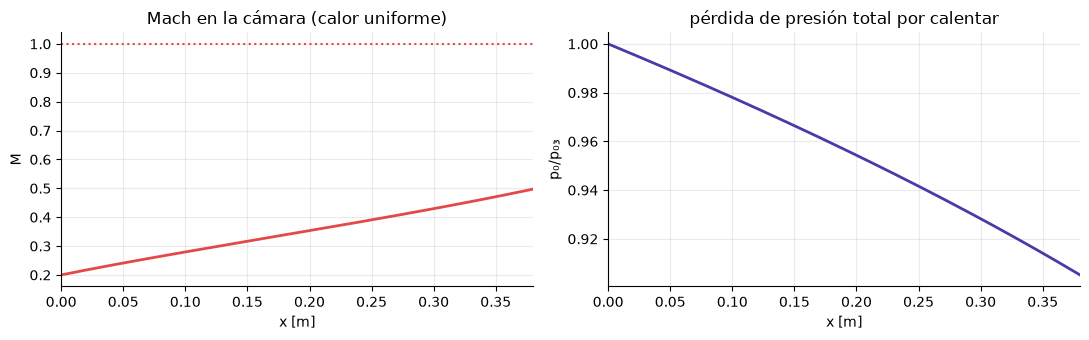

M4 = 0.497   p04/p03 = 0.9052   (límite de Rayleigh con M3 = 0.20: T0 x 5.91)


In [16]:
def widget_rayleigh(M3=0.2, razon_T0=4.0, cf=0.003):
    L, D = 0.38, 0.18
    xs = np.linspace(0, L, 200)
    q = (razon_T0 - 1)/L
    def f(x, y):
        M2, lnp0, T0 = y
        return [dM2_dx(M2, 1.33, 0, q/T0, 4*cf/D, 0), dlnp0_dx(M2, 1.33, q/T0, 4*cf/D), q]
    ev = lambda x, y: y[0] - 0.995**2
    ev.terminal = True
    s = solve_ivp(f, [0, L], [M3**2, 0.0, 1.0], events=ev, max_step=L/200, rtol=1e-8)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    a1.plot(s.t, np.sqrt(s.y[0]), color=COL["gas"], lw=2); a1.axhline(1, color=COL["aviso"], ls=":")
    a1.set_xlabel("x [m]"); a1.set_ylabel("M"); a1.set_xlim(0, L); a1.set_title("Mach en la cámara (calor uniforme)")
    a2.plot(s.t, np.exp(s.y[1]), color=COL["choque"], lw=2); a2.set_xlabel("x [m]"); a2.set_ylabel("p₀/p₀₃"); a2.set_xlim(0, L)
    a2.set_title("pérdida de presión total por calentar")
    plt.tight_layout(); plt.show()
    T0max = 1/rayleigh_T0(M3, 1.33)
    if s.status == 1:
        print("ESTRANGULAMIENTO TÉRMICO en x = %.3f m: con M3 = %.2f solo se puede multiplicar T0 por %.2f" % (s.t[-1], M3, T0max))
    else:
        print("M4 = %.3f   p04/p03 = %.4f   (límite de Rayleigh con M3 = %.2f: T0 x %.2f)" % (math.sqrt(s.y[0, -1]), math.exp(s.y[1, -1]), M3, T0max))
w3 = dict(M3=FloatSlider(value=0.2, min=0.05, max=0.45, step=0.01, description="M₃", continuous_update=False),
          razon_T0=FloatSlider(value=4.0, min=1.0, max=8.0, step=0.1, description="T₀₄/T₀₃", continuous_update=False),
          cf=FloatSlider(value=0.003, min=0.0, max=0.01, step=0.001, description="c_f", continuous_update=False))
display(VBox([HBox(list(w3.values())), interactive_output(widget_rayleigh, w3)]))

## 6. Combustión: por qué hace falta un estabilizador de llama

🎓 La entrega suma el calor con $T_{04}=T_{02}+\eta_b f\,\text{LHV}/[(1+f)c_p]$, con $c_p$ y $\gamma=1.4$ constantes. Aquí la química entra por tres caminos, todos con **Cantera**:

1. **Termodinámica de los productos.** Con equilibrio HP con las bases NASA/GRI del mecanismo de cada combustible, $c_p$ y $\gamma$ cambian con la temperatura y la disociación.
2. **Cinética en el tiempo (autoignición y reactor agitado).** El aire de la cámara llega a ~400 K. Un reactor a presión constante muestra que la mezcla **no** se autoenciende en los ~5 ms que pasa en la cámara. El estabilizador en V crea una zona de recirculación de tiempo de residencia $\tau_{res}=L_r w/u_{borde}$. Se modela como un **reactor perfectamente agitado (PSR)**, integrado en el tiempo hasta el estado estacionario. Si $\tau_{res}$ es menor que el tiempo mínimo para el que el PSR sigue encendido, la llama **se apaga**.
3. **Llama laminar → frente turbulento.** La velocidad laminar $S_L$ se obtiene de una llama 1D con cinética detallada (Cantera `FreeFlame`, tabulada en `data/ramjet_cinetica.json`). De ahí sale la velocidad turbulenta y el ángulo con que el frente se abre desde cada estabilizador:

$$S_T=S_L\left[1+C\left(\frac{u'}{S_L}\right)^{n}\right],\qquad \tan\theta=\frac{S_T}{u_{borde}},\qquad b(x)=\frac{1}{A_{cc}}\left|\bigcup_k\left\{r:\ |r-r_k|\le\tfrac{w}{2}+x\tan\theta\right\}\right|_{\text{área}}$$

La fracción quemada al final de la cámara es la **eficiencia de combustión** $\eta_b=b(L)$. Su perfil $b(x)$ es la fuente de calor en la EDO de la §5. SUPUESTOS: $u'=0.1u_3$, $C=1.5$, $n=0.7$ y $L_r=4w$. Para los combustibles líquidos $S_L$ viene de la correlación de Metghalchi–Keck.

In [18]:
# === Combustibles (mecanismos de Cantera) y estado de salida de cámara ===
COMBUSTIBLES = {
    "Hidrógeno": dict(mech="gri30.yaml", sp="H2", ox="O2:1, N2:3.76"),
    "Metano": dict(mech="gri30.yaml", sp="CH4", ox="O2:1, N2:3.76"),
    "Jet A-1 (n-heptano)": dict(mech=os.path.join("data", "nheptane_lu88sk.yaml"), sp="nc7h16", ox="o2:1, n2:3.76"),
    "Octano (iso-octano)": dict(mech=os.path.join("data", "isooctane_yoo2013.yaml"), sp="IC8H18", ox="O2:1, N2:3.76"),
}
_SOL = {}
def sol(nombre):
    c = COMBUSTIBLES[nombre]
    if c["mech"] not in _SOL:
        _SOL[c["mech"]] = ct.Solution(c["mech"])
    return _SOL[c["mech"]]

def mezcla(nombre, phi, T_aire, p, T_comb=300.0):
    """Aire a T_aire + combustible gaseoso a T_comb, mezcla adiabatica. Devuelve gas, f, f_st, h, Y."""
    c = COMBUSTIBLES[nombre]; g = sol(nombre)
    g.TPX = T_aire, p, c["ox"]; ha = g.enthalpy_mass; Ya = g.Y.copy()
    g.TPX = T_comb, p, c["sp"] + ":1"; hf = g.enthalpy_mass; Yf = g.Y.copy()
    g.set_equivalence_ratio(1.0, c["sp"] + ":1", c["ox"]); Yst = g.Y.copy()
    k = g.species_index(c["sp"]); f_st = Yst[k]/(1 - Yst[k])
    f = phi*f_st
    Y = (Ya + f*Yf)/(1 + f); h = (ha + f*hf)/(1 + f)
    g.HPY = h, p, Y
    return g, f, f_st, h, Y

def productos(nombre, phi, T_aire, p, eta_b=1.0):
    """Salida de camara: entalpia total conservada; fraccion eta_b del avance hacia el equilibrio."""
    g, f, f_st, h, Y0 = mezcla(nombre, phi, T_aire, p)
    g.HPY = h, p, Y0; g.equilibrate("HP"); Yeq = g.Y.copy(); Teq = g.T
    Y = Y0 + eta_b*(Yeq - Y0)
    g.HPY = h, p, Y
    return dict(T=g.T, Teq=Teq, Y=Y, h=h, f=f, f_st=f_st, cp=g.cp_mass, R=ct.gas_constant/g.mean_molecular_weight,
                gamma=g.cp_mass/g.cv_mass)

In [19]:
# === Cinética química: autoignición, reactor agitado (estabilizador) y velocidad de llama ===
def psr(comb, phi, T, p, tau):
    """Estabilizador de llama como reactor perfectamente agitado (zona de recirculacion): EDO en el tiempo
    hasta el estado estacionario. Devuelve la temperatura del reactor (si se apaga, vuelve a T)."""
    c = COMBUSTIBLES[comb]; g = ct.Solution(c["mech"])
    g.set_equivalence_ratio(phi, c["sp"] + ":1", c["ox"]); g.TP = T, p
    entrada = ct.Reservoir(g, clone=True)
    g.equilibrate("HP")
    r = ct.IdealGasReactor(g, clone=True); r.volume = 1e-3
    salida = ct.Reservoir(g, clone=True)
    mfc = ct.MassFlowController(entrada, r, mdot=r.mass/tau)
    ct.PressureController(r, salida, primary=mfc, K=1e-5)
    net = ct.ReactorNet([r])
    try:
        net.advance_to_steady_state(max_steps=50000)
    except ct.CanteraError:
        pass
    return r.phase.T

def psr_apagado(comb, phi, T, p, tau_lo=1e-6, tau_hi=1e-1):
    """Tiempo de residencia minimo para sostener la llama (limite de apagado), biseccion logaritmica."""
    vivo = lambda tau: psr(comb, phi, T, p, tau) > T + 300
    if not vivo(tau_hi):
        return float("inf")
    a, b = math.log(tau_lo), math.log(tau_hi)
    for _ in range(16):
        m = 0.5*(a + b)
        if vivo(math.exp(m)): b = m
        else: a = m
    return math.exp(b)

def retardo_ignicion(comb, phi, T, p, t_max=0.05):
    """Autoignicion de la mezcla homogenea a presion constante (EDO en el tiempo, cinetica detallada)."""
    c = COMBUSTIBLES[comb]; g = ct.Solution(c["mech"])
    g.set_equivalence_ratio(phi, c["sp"] + ":1", c["ox"]); g.TP = T, p
    r = ct.IdealGasConstPressureReactor(g, clone=True); net = ct.ReactorNet([r])
    tt, TT = [0.0], [T]
    while net.time < t_max:
        net.step(); tt.append(net.time); TT.append(r.phase.T)
        if r.phase.T > T + 400:
            break
    tau = tt[-1] if TT[-1] > T + 400 else float("inf")
    return tau, np.array(tt), np.array(TT)

try:
    CIN = json.load(open(os.path.join("data", "ramjet_cinetica.json")))
except FileNotFoundError:
    CIN = {"T_ref": 400.0, "p_ref": 1.8e5, "SL": {}, "tau_apagado": {}}

def vel_laminar(comb, phi, T, p):
    """S_L: tabla de Cantera (FreeFlame, cinetica detallada) para H2 y CH4; correlacion de
    Metghalchi-Keck (iso-octano) para los liquidos. Escala con (T/T_ref)^a (p/p_ref)^b."""
    tab = CIN["SL"].get(comb, {})
    if tab:
        ph = sorted(tab, key=float)
        s0 = float(np.interp(phi, [float(k) for k in ph], [tab[k] for k in ph]))
        Tr, pr = CIN["T_ref"], CIN["p_ref"]
    else:
        fl = min(max(phi, 0.7), 1.4)
        s0 = max(0.263 - 0.847*(fl - 1.13)**2, 0.02)
        Tr, pr = 298.0, 101325.0
        if phi < 0.7:
            s0 *= max(phi/0.7, 0.0)**4          # SUPUESTO: caida hacia el limite pobre
    a = 2.18 - 0.8*(phi - 1.0); b = -0.16 + 0.22*(phi - 1.0)
    return s0*(T/Tr)**a*(p/pr)**b

def tau_apagado(comb, phi, T3, p3):
    tab = CIN["tau_apagado"].get(comb, {})
    if not tab:
        return 0.0
    ph = sorted(tab, key=float)
    tv = [tab[k] if (tab[k] is not None and tab[k] < 1) else 1.0 for k in ph]
    phf = [float(k) for k in ph]
    lt = float(np.interp(min(max(phi, phf[0]), phf[-1]), phf, np.log(tv)))
    # SUPUESTO: tiempo quimico ~ 1/p (bimolecular) y Arrhenius global Ea/R = 12000 K
    return math.exp(lt)*(CIN["p_ref"]/p3)*math.exp(12000.0*(1/T3 - 1/CIN["T_ref"]))

In [20]:
# === Geometría corregida del motor y frente de llama turbulento desde los estabilizadores en V ===
GEO = dict(cono=25.0, M_dis=2.0, r_lab=0.060, r_cc=0.090, L_dif=0.32, L_cc=0.38, r_g=0.072, r_s=0.094,
           cf=0.003, m_buzz=0.85)
# estabilizadores en V (dos anillos) y frente turbulento
LLAMA = dict(n_anillos=2, w_g=0.015, r_g=(0.040, 0.072), I=0.12, C=1.5, n=0.7, L_r=4.0)
def llama(comb, phi, T3, p3, u3, L, r_cc, ll=LLAMA):
    """Frente turbulento anclado en estabilizadores en V: S_T = S_L (1 + C (u'/S_L)^n), tan(theta) = S_T/u_borde,
    ancho quemado W(x) = w_g + 2 x tan(theta); fraccion quemada b(x) = min(1, sum 2 pi r_g W / A)."""
    Acc = math.pi*r_cc**2
    anillos = ll["r_g"][:ll["n_anillos"]]
    bloqueo = sum(2*math.pi*r*ll["w_g"] for r in anillos)/Acc
    u_b = u3/(1 - bloqueo)
    SL = vel_laminar(comb, phi, T3, p3)
    up = ll["I"]*u3
    ST = SL*(1 + ll["C"]*(up/max(SL, 1e-4))**ll["n"]) if SL > 1e-3 else 0.0
    tth = ST/u_b
    def b(x):
        # union de las bandas anulares quemadas [r - W/2, r + W/2], W = w_g + 2 x tan(theta), recortadas a [0, r_cc]
        W = ll["w_g"] + 2*x*tth
        bandas = sorted((max(r - W/2, 0.0), min(r + W/2, r_cc)) for r in anillos)
        area, (a0, b0) = 0.0, bandas[0]
        for a1, b1 in bandas[1:]:
            if a1 <= b0: b0 = max(b0, b1)
            else: area += math.pi*(b0**2 - a0**2); a0, b0 = a1, b1
        area += math.pi*(b0**2 - a0**2)
        return min(1.0, area/Acc)
    return dict(bloqueo=bloqueo, u_borde=u_b, SL=SL, ST=ST, theta=math.degrees(math.atan(tth)), b=b,
                eta_b=b(L), tau_res=ll["L_r"]*ll["w_g"]/u_b, K_fh=1.6*(bloqueo/(1 - bloqueo))**2)

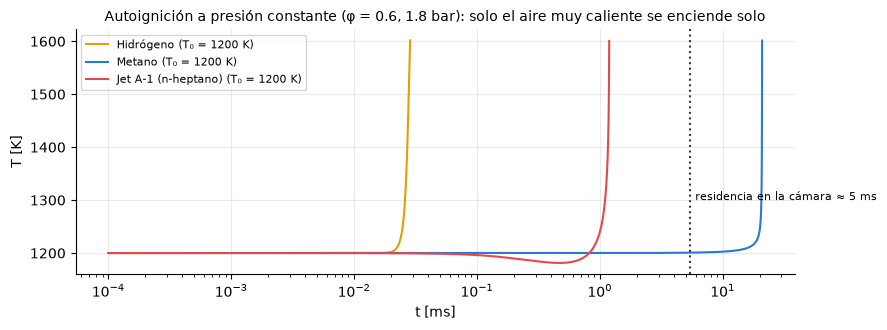

,combustible,T inicial [K],retardo de ignición [ms]
0,Hidrógeno,400.0,inf
1,Hidrógeno,800.0,inf
2,Hidrógeno,1200.0,0.029
3,Metano,400.0,inf
4,Metano,800.0,inf
5,Metano,1200.0,20.880
6,Jet A-1 (n-heptano),400.0,inf
7,Jet A-1 (n-heptano),800.0,inf
8,Jet A-1 (n-heptano),1200.0,1.191


Tiempo mínimo de residencia del PSR para sostener la llama [ms] (T = 400 K, p = 1.8 bar):


,φ = 0.6,φ = 0.8,φ = 1.0,φ = 1.2
Hidrógeno,0.0173,0.0122,0.0109,0.0103
Metano,0.5266,0.1421,0.1282,0.1771
Jet A-1 (n-heptano),0.1279,0.0468,0.0311,0.0319
Octano (iso-octano),0.1774,0.0616,0.0380,0.0374


In [21]:
# Autoignición de la mezcla homogénea a la entrada de la cámara (M=2, 10 km: T3 ~ 400 K, p3 ~ 1.8 bar) y con 700 K
filas = []
fig, ax = plt.subplots(figsize=(9, 3.4))
for comb in ["Hidrógeno", "Metano", "Jet A-1 (n-heptano)"]:
    for T in (400.0, 800.0, 1200.0):
        tau, tt, TT = retardo_ignicion(comb, 0.6, T, 1.8e5, t_max=0.05)
        filas.append((comb, T, tau*1e3 if tau < 1 else np.inf))
        if T == 1200.0:
            ax.semilogx(np.maximum(tt, 1e-7)*1e3, TT, color=COLC[comb], label=comb + " (T₀ = 1200 K)")
ax.axvline(0.38/70*1e3, color=COL["tinta"], ls=":"); ax.text(0.38/70*1e3*1.1, 1300, "residencia en la cámara ≈ 5 ms", fontsize=8)
ax.set_xlabel("t [ms]"); ax.set_ylabel("T [K]"); ax.legend(fontsize=8); ax.set_title("Autoignición a presión constante (φ = 0.6, 1.8 bar): solo el aire muy caliente se enciende solo", fontsize=10)
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas, columns=["combustible", "T inicial [K]", "retardo de ignición [ms]"]).round(3))
TA = pd.DataFrame({c: CIN["tau_apagado"][c] for c in CIN["tau_apagado"]}).T
TA.columns = ["φ = " + k for k in TA.columns]
print("Tiempo mínimo de residencia del PSR para sostener la llama [ms] (T = 400 K, p = 1.8 bar):")
display((TA*1e3).round(4))

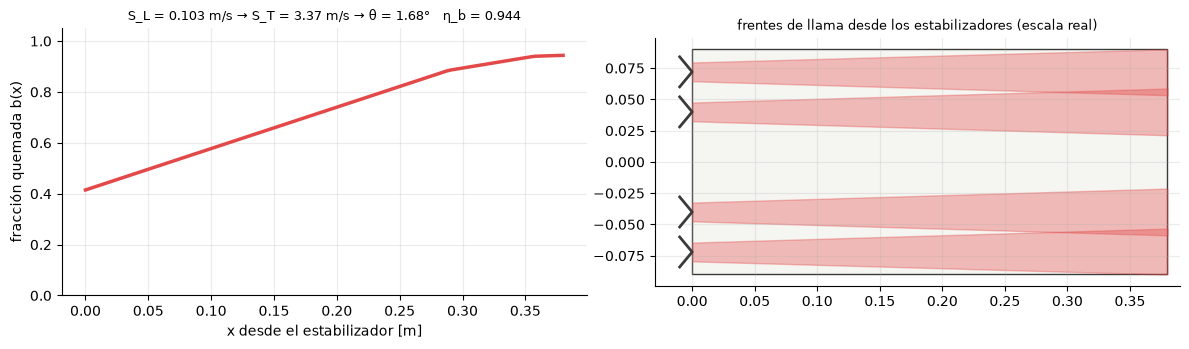

bloqueo = 41 %  pérdida K = 0.80  τ_res = 0.524 ms  τ_apagado = 0.132 ms  → LLAMA ESTABLE


In [22]:
def widget_camara(comb="Jet A-1 (n-heptano)", phi=0.6, n_anillos=2, L_cc=0.38):
    T3, p3, u3 = 399.4, 1.83e5, 67.0
    ll = dict(LLAMA); ll["n_anillos"] = n_anillos
    fl = llama(comb, phi, T3, p3, u3, L_cc, GEO["r_cc"], ll)
    tbo = tau_apagado(comb, max(phi, 0.6), T3, p3)
    xs = np.linspace(0, L_cc, 120)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
    a1.plot(xs, [fl["b"](x) for x in xs], color=COLC[comb], lw=2.5)
    a1.set_xlabel("x desde el estabilizador [m]"); a1.set_ylabel("fracción quemada b(x)"); a1.set_ylim(0, 1.05)
    a1.set_title("S_L = %.3f m/s → S_T = %.2f m/s → θ = %.2f°   η_b = %.3f" % (fl["SL"], fl["ST"], fl["theta"], fl["eta_b"]), fontsize=9)
    Rc = GEO["r_cc"]
    a2.add_patch(plt.Rectangle((0, -Rc), L_cc, 2*Rc, fc="#f5f5f2", ec=COL["tinta"]))
    for r in ll["r_g"][:n_anillos]:
        for sg in (1, -1):
            x = np.array([0, L_cc]); w = ll["w_g"]/2 + x*math.tan(math.radians(fl["theta"]))
            a2.fill_between(x, sg*np.clip(r - w, 0, Rc), sg*np.clip(r + w, 0, Rc), color=COL["gas"], alpha=0.35)
            a2.plot([-0.01, 0.0, -0.01], [sg*(r + 0.012), sg*r, sg*(r - 0.012)], color=COL["tinta"], lw=2)
    a2.set_aspect("equal"); a2.set_xlim(-0.03, L_cc + 0.01); a2.set_ylim(-Rc*1.1, Rc*1.1); a2.set_title("frentes de llama desde los estabilizadores (escala real)", fontsize=9)
    plt.tight_layout(); plt.show()
    estado = "LLAMA ESTABLE" if fl["tau_res"] > tbo else "APAGADO: el estabilizador no retiene el gas el tiempo suficiente"
    print("bloqueo = %.0f %%  pérdida K = %.2f  τ_res = %.3f ms  τ_apagado = %.3f ms  → %s" % (100*fl["bloqueo"], fl["K_fh"], 1e3*fl["tau_res"], 1e3*tbo, estado))
w4 = dict(comb=Dropdown(options=list(COMBUSTIBLES), value="Jet A-1 (n-heptano)", description="combustible"),
          phi=FloatSlider(value=0.6, min=0.3, max=1.2, step=0.05, description="φ", continuous_update=False),
          n_anillos=IntSlider(value=2, min=1, max=2, description="anillos"),
          L_cc=FloatSlider(value=0.38, min=0.15, max=0.8, step=0.01, description="L cámara [m]", continuous_update=False))
display(VBox([HBox([w4["comb"], w4["phi"]]), HBox([w4["n_anillos"], w4["L_cc"]]), interactive_output(widget_camara, w4)]))

## 7. Tobera convergente-divergente con gas real

La garganta es el punto de **máximo flujo másico por unidad de área** a lo largo de la isentrópica que parte del estado de salida de la cámara. Con Cantera no hace falta suponer $\gamma$. Se buscan $\max_p(\rho u)$, con $u=\sqrt{2(h_{04}-h(s_{04},p))}$, y la presión de salida supersónica que cumple $\rho_6u_6A_6=\dot m_g$. Hay dos límites:
- **expansión congelada:** composición fija, el caso más realista en toberas cortas;
- **expansión en equilibrio:** la composición se recombina al enfriarse y libera algo de energía química.

In [24]:
# === Tobera C-D real: capacidad de la garganta y estado de salida (Cantera, congelada/equilibrio) ===
def tobera(nombre, Y, T0, p0, A5, A6, modo="congelado"):
    """Expansion isentropica real (Cantera): capacidad de la garganta y estado de salida supersonico."""
    g = sol(nombre)
    g.TPY = T0, p0, Y; s0 = g.entropy_mass; h0 = g.enthalpy_mass; Y0 = g.Y.copy()
    def estado(p):
        g.SPY = s0, p, Y0
        if modo != "congelado":
            g.equilibrate("SP")
        u = math.sqrt(max(2*(h0 - g.enthalpy_mass), 0.0))
        gam = g.cp_mass/g.cv_mass
        return dict(p=p, T=g.T, rho=g.density, u=u, G=g.density*u, gam=gam,
                    a=math.sqrt(gam*ct.gas_constant/g.mean_molecular_weight*g.T))
    a, b = 0.35*p0, 0.75*p0; gr = (math.sqrt(5) - 1)/2       # garganta: maximo de rho*u (seccion aurea)
    c_, d_ = b - gr*(b - a), a + gr*(b - a)
    for _ in range(40):
        if estado(c_)["G"] > estado(d_)["G"]: b = d_
        else: a = c_
        c_, d_ = b - gr*(b - a), a + gr*(b - a)
    st = estado(0.5*(a + b))
    def salida(mdot):
        pe = brentq(lambda p: estado(p)["G"] - mdot/A6, 1e-4*p0, st["p"]*0.9999)
        return estado(pe)
    return dict(cap=st["G"]*A5, garganta=st, salida=salida, estado=estado)

## 8. El motor ensamblado

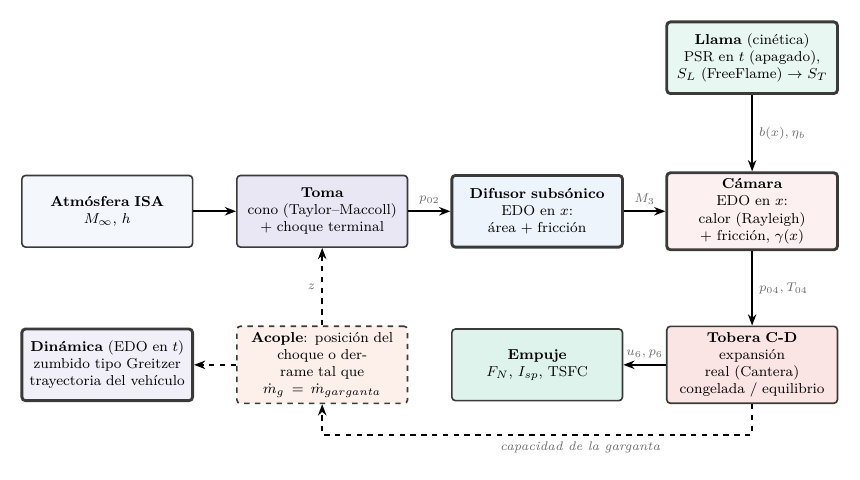

In [26]:
# === Motor completo: toma + difusor + llama + cámara 1D + tobera real, acoplados por la garganta sónica ===
_CACHE_TOMA = {}
def toma(Minf, geo=GEO):
    k = (round(Minf, 3), geo["cono"], geo["M_dis"], geo["r_lab"])
    if k not in _CACHE_TOMA:
        _CACHE_TOMA[k] = toma_externa(Minf, geo["cono"], geo["M_dis"], geo["r_lab"])
    return _CACHE_TOMA[k]

def camara_1d(M3, T03, T04, g_in, g_out, L, r_cc, cf, prof):
    """Camara de area constante: EDO cuasi-1D en x con adicion de calor (perfil prof), friccion y gamma variable."""
    Dh = 2*r_cc
    def dT0(x):
        a, b = max(x/L - 1e-4, 0.0), min(x/L + 1e-4, 1.0)
        return (T04 - T03)*(prof(b) - prof(a))/((b - a)*L)
    def f(x, y):
        M2, lnp0 = y
        s = prof(x/L); T0 = T03 + (T04 - T03)*s; g = g_in + (g_out - g_in)*s
        dlnT0 = dT0(x)/T0
        return [dM2_dx(M2, g, 0.0, dlnT0, 4*cf/Dh, 0.0), dlnp0_dx(M2, g, dlnT0, 4*cf/Dh)]
    ev = lambda x, y: y[0] - 0.97**2
    ev.terminal = True; ev.direction = 1
    s = solve_ivp(f, [0, L], [M3**2, 0.0], rtol=1e-7, atol=1e-10, events=ev, max_step=L/40, dense_output=True)
    return dict(M4=math.sqrt(s.y[0, -1]), p0r=math.exp(s.y[1, -1]), choque_termico=s.status == 1, sol=s)

def punto(Minf, h, comb, phi, geo=GEO, dT=0.0, modo="congelado", detalle=False, ll=LLAMA, ciclo=False):
    """Punto de operacion: acople toma-camara-tobera. La incognita es la posicion del choque terminal
    (supercritico, z > 0) o el caudal derramado (subcritico, z < 0)."""
    T, p, rho = isa(h, dT); g = 1.4
    u = Minf*math.sqrt(g*R_AIRE*T); T0 = T*(1 + 0.2*Minf**2); p0 = p*(1 + 0.2*Minf**2)**3.5
    tm = toma(Minf, geo)
    Ac = math.pi*geo["r_lab"]**2; A0 = tm["A0Ac"]*Ac; m_max = rho*u*A0
    Acc = math.pi*geo["r_cc"]**2; A5 = math.pi*geo["r_g"]**2; A6 = math.pi*geo["r_s"]**2
    p01 = p0*tm["p0_cono"]; Mc = tm["Mc"]
    Ae = m_max*math.sqrt(T0)/(p01*flujo_masico_param(Mc))     # entrada interna del labio
    Ms_max = mach_area(area_mach(Mc)*Acc/Ae, "sup") if Acc > Ae else Mc
    f = phi*mezcla(comb, 1.0, T0, p0)[2]
    def estado(z):
        if z <= 0:
            mr = 1.0 + 0.7*z; Ms = Mc
        else:
            mr = 1.0; Ms = Mc + z*(Ms_max - Mc)
        ma = mr*m_max; n = choque_normal(Ms); p02n = p01*n["p0r"]
        A_ns = ma*math.sqrt(T0)/(p02n*flujo_masico_param(n["M2"]))
        if A_ns >= Acc:
            return None
        Md, pr_f = difusor_subsonico(n["M2"], A_ns, Acc, geo["L_dif"], 2*geo["r_cc"], geo["cf"])
        p02 = p02n*pr_f
        mg = ma*(1 + f)
        M3 = mach_area(Acc/(mg*math.sqrt(T0)/(p02*flujo_masico_param(1.0))), "sub")
        T3 = T0*isen(M3)["T"]; p3 = p02*isen(M3)["p"]; u3 = M3*math.sqrt(g*R_AIRE*T3)
        fl = llama(comb, phi, T3, p3, u3, geo["L_cc"], geo["r_cc"], ll)
        tau_bo = tau_apagado(comb, max(phi, 0.6), T3, p3)
        apagada = fl["tau_res"] < tau_bo or fl["eta_b"] <= 1e-3
        eta = 0.0 if apagada else 0.99*fl["eta_b"]
        prod = productos(comb, phi, T0, p3, eta)
        p03 = p02 - fl["K_fh"]*p3*0.5*g*M3**2
        if p03 < 0.5*p02 or M3 > 0.6:            # la camara no puede pasar el flujo (perdidas excesivas)
            return dict(ma=ma, mg=mg, mr=mr, Ms=Ms, res=+1e3, choque_termico=True)
        bL = max(fl["b"](geo["L_cc"]), 1e-6)
        prof = lambda xi: fl["b"](xi*geo["L_cc"])/bL
        cam = camara_1d(M3, T0, prod["T"], 1.4, prod["gamma"], geo["L_cc"], geo["r_cc"], geo["cf"], prof)
        if cam["choque_termico"]:
            return dict(ma=ma, mg=mg, mr=mr, Ms=Ms, res=+1e3, choque_termico=True)
        p04 = p03*cam["p0r"]
        tb = tobera(comb, prod["Y"], prod["T"], p04, A5, A6, modo)
        return dict(ma=ma, mg=mg, mr=mr, Ms=Ms, p02=p02, p03=p03, p04=p04, M3=M3, M4=cam["M4"], Md=Md, T3=T3,
                    p3=p3, u3=u3, tb=tb, cam=cam, prod=prod, fl=fl, tau_bo=tau_bo, apagada=apagada,
                    res=(mg - tb["cap"])/mg, choque_termico=False)
    def res(z):
        e = estado(z)
        return 1e3 if e is None else e["res"]
    if ciclo:
        # ciclo ideal acoplado (como la tesis de Dallos): toma critica, garganta variable, tobera adaptada
        e = estado(0.0)
        if e is None or e.get("choque_termico"):
            return dict(ok=False, regimen="inoperable", Minf=Minf, h=h, phi=phi)
        sal = e["tb"]["estado"](p)
        mf = e["ma"]*f; Fn = e["mg"]*sal["u"] - e["ma"]*u
        return dict(ok=True, regimen="ciclo ideal", Minf=Minf, h=h, phi=phi, f=f, ma=e["ma"], mf=mf, Fn=Fn,
                    F_esp=Fn/e["ma"], Isp=Fn/(mf*G0), TSFC=3600*mf/Fn if Fn > 0 else float("nan"),
                    T04=e["prod"]["T"], u6=sal["u"], u=u, pi_d=e["p02"]/p0, eta_b=e["fl"]["eta_b"],
                    eta_o=Fn*u/(mf*(e["prod"]["h"] and 1.0)) if False else None)
    if res(-1.0) > 0:
        regimen, z = "desarranque subcrítico", -1.0
    elif res(1.0) < 0:
        regimen, z = "choque tragado (supercrítico extremo)", 1.0
    else:
        z = brentq(res, -1.0, 1.0, xtol=1e-5)
        regimen = "supercrítico" if z > 1e-3 else ("subcrítico" if z < -1e-3 else "crítico")
    e = estado(z)
    if e is None or e.get("choque_termico") or "tb" not in e:
        return dict(ok=False, regimen="inoperable (choque térmico o desarranque)", Minf=Minf, h=h, phi=phi)
    if e["apagada"]:
        regimen = "llama apagada"
    elif e["mr"] < geo["m_buzz"]:
        regimen = "subcrítico (zona de zumbido)"
    sal = e["tb"]["salida"](e["mg"])
    # SUPUESTO: arrastre aditivo por derrame ~ sobrepresion tras el choque normal sobre el area derramada
    D_add = max(p*tm["p_s"]*choque_normal(Mc)["p21"] - p, 0.0)*(A0 - e["ma"]/(rho*u)) if e["mr"] < 1 else 0.0
    Fg = e["mg"]*sal["u"] + (sal["p"] - p)*A6
    Fn = Fg - e["ma"]*u - D_add
    mf = e["ma"]*f
    out = dict(ok=True, regimen=regimen, z=z, Minf=Minf, h=h, T=T, p=p, u=u, T0=T0, p0=p0, ma=e["ma"], mf=mf,
               mg=e["mg"], m_max=m_max, mr=e["mr"], Ms=e["Ms"], Mc=Mc, pi_d=e["p02"]/p0, p02=e["p02"],
               p03=e["p03"], p04=e["p04"], T04=e["prod"]["T"], Teq=e["prod"]["Teq"], M3=e["M3"], M4=e["M4"],
               T3=e["T3"], p3=e["p3"], u3=e["u3"], eta_b=e["fl"]["eta_b"], theta=e["fl"]["theta"], SL=e["fl"]["SL"],
               tau_res=e["fl"]["tau_res"], tau_bo=e["tau_bo"], M6=sal["u"]/sal["a"], u6=sal["u"], p6=sal["p"],
               T6=sal["T"], Fg=Fg, Fn=Fn, D_add=D_add, Isp=Fn/(mf*G0) if mf > 0 else float("nan"),
               TSFC=3600*mf/Fn if Fn > 0 else float("nan"), f=f, phi=phi, F_esp=Fn/e["ma"],
               eta_p=2*u/(sal["u"] + u))
    if detalle:
        out.update(cam=e["cam"], tb=e["tb"], salida=sal, toma=tm, prod=e["prod"], fl=e["fl"])
    return out

def caracteristica_toma(mr, mb=0.85, c1=0.10, c2=1.6):
    """Recuperacion relativa pi/pi_c entregada por la toma vs caudal relativo m/m_max.
    supercritico (mr > 1): la recuperacion cae casi en vertical (caudal fijo);
    subcritico estable (mb < mr < 1): pendiente negativa suave (el derrame sube un poco la recuperacion);
    mas alla del umbral de zumbido (mr < mb): pendiente positiva -> inestable, como la oleada de un compresor
    (forma en S de Greitzer: la recuperacion vuelve a subir con flujo inverso, lo que cierra el ciclo limite)."""
    if mr >= 1.0:
        return 1.0 - 25.0*(mr - 1.0)
    if mr >= mb:
        return 1.0 + c1*(1.0 - mr)
    d = mb - mr                                  # rama en S (cubica): minimo en d = 0.4, sube con flujo inverso
    return 1.0 + c1*(1.0 - mb) - c2*d + c2/0.48*d**3

def mapa_motor(comb, h, Ms, phis, geo=GEO):
    """Mapa del motor de geometria fija: empuje, consumo, regimen y margen de la toma en (M, phi)."""
    campos = ["F", "mf", "Isp", "TSFC", "mr", "pi_d", "T04", "eta_b"]
    out = {c: np.full((len(Ms), len(phis)), np.nan) for c in campos}
    out["reg"] = [[None]*len(phis) for _ in Ms]
    for i, M in enumerate(Ms):
        for j, ph in enumerate(phis):
            o = punto(M, h, comb, ph, geo)
            out["reg"][i][j] = o["regimen"]
            if o["ok"]:
                for c, k in zip(campos, ["Fn", "mf", "Isp", "TSFC", "mr", "pi_d", "T04", "eta_b"]):
                    out[c][i, j] = o[k]
    out["M"], out["phi"], out["h"] = np.array(Ms), np.array(phis), h
    return out

In [27]:
CACHE = {}
RUTA_CACHE = os.path.join("data", "ramjet_resultados.json")
def _json(v):
    if isinstance(v, np.ndarray): return v.tolist()
    if isinstance(v, dict): return {k: _json(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)): return [_json(x) for x in v]
    if isinstance(v, (np.floating,)): return float(v)
    return v
def _np(v):
    if isinstance(v, dict): return {k: _np(x) for k, x in v.items()}
    if isinstance(v, list) and v and all(isinstance(x, (int, float)) or x is None for x in v):
        return np.array([np.nan if x is None else x for x in v], dtype=float)
    if isinstance(v, list) and v and all(isinstance(x, list) and x and isinstance(x[0], (int, float)) for x in v):
        return np.array(v, dtype=float)
    return v
def correr(clave, fn):
    if clave not in CACHE:
        CACHE[clave] = _np(_json(fn()))
        try: json.dump(_json(CACHE), open(RUTA_CACHE, "w"))
        except Exception as e: print("no se pudo guardar la caché:", e)
    return CACHE[clave]
def cargar_cache():
    if os.path.exists(RUTA_CACHE):
        CACHE.update({k: _np(v) for k, v in json.load(open(RUTA_CACHE)).items()})
    return list(CACHE)

In [28]:
print("caché:", cargar_cache())
o = punto(2.0, 10000.0, "Jet A-1 (n-heptano)", 0.6, detalle=True)
est = pd.DataFrame([("∞ aire libre", 2.0, o["T"], o["p"]/1e3, o["p0"]/1e3), ("3 entrada a cámara", o["M3"], o["T3"], o["p3"]/1e3, o["p03"]/1e3),
                    ("4 salida de cámara", o["M4"], o["T04"], np.nan, o["p04"]/1e3), ("6 salida de tobera", o["M6"], o["T6"], o["p6"]/1e3, np.nan)],
                   columns=["estación", "M", "T [K]", "p [kPa]", "p₀ [kPa]"])
display(est.round(3))
print("Régimen: %s (caudal %.3f kg/s = %.1f %% de la captura)  recuperación de la toma π_d = %.3f" % (o["regimen"], o["ma"], 100*o["mr"], o["pi_d"]))
print("η_b = %.3f  T04 = %.0f K (equilibrio %.0f K)  F_N = %.0f N  Isp = %.0f s  TSFC = %.3f kg/(N·h)  p6/pa = %.3f" %
      (o["eta_b"], o["T04"], o["Teq"], o["Fn"], o["Isp"], o["TSFC"], o["p6"]/o["p"]))
# Misma cámara con la garganta de la entrega: la toma ya no acepta mezclas ricas
GEO_E = dict(GEO); GEO_E["r_g"], GEO_E["r_s"] = 0.0699, 0.092
comp = []
for ph in (0.45, 0.6, 0.8):
    a = punto(2.0, 10000.0, "Jet A-1 (n-heptano)", ph); b = punto(2.0, 10000.0, "Jet A-1 (n-heptano)", ph, GEO_E)
    comp.append((ph, a["regimen"], a["mr"], a["Fn"], b["regimen"], b["mr"], b["Fn"]))
display(pd.DataFrame(comp, columns=["φ", "diseño corregido", "ṁ/ṁmax", "F_N [N]", "garganta de la entrega (139.7 mm)", "ṁ/ṁmax ", "F_N [N] "]).round(3))

caché: ['mapa_Hidrógeno', 'mapa_Metano', 'mapa_Jet A-1 (n-heptano)', 'mapa_Octano (iso-octano)', 'dallos']


,estación,M,T [K],p [kPa],p₀ [kPa]
0,∞ aire libre,2.000,223.150,26.436,206.849
1,3 entrada a cámara,0.171,399.328,186.701,187.480
2,4 salida de cámara,0.233,1699.745,NaN,184.597
3,6 salida de tobera,1.946,1099.438,26.040,NaN


Régimen: subcrítico (caudal 2.735 kg/s = 97.8 % de la captura)  recuperación de la toma π_d = 0.921
η_b = 0.943  T04 = 1700 K (equilibrio 1785 K)  F_N = 1887 N  Isp = 1768 s  TSFC = 0.208 kg/(N·h)  p6/pa = 0.985


,φ,diseño corregido,ṁ/ṁmax,F_N [N],garganta de la entrega (139.7 mm),ṁ/ṁmax,F_N [N]
0,0.45,supercrítico,1.000,1364.411,supercrítico,1.000,1414.357
1,0.60,subcrítico,0.978,1887.211,subcrítico,0.925,1734.375
2,0.80,subcrítico,0.876,1977.384,subcrítico (zona de zumbido),0.828,1818.375


**V3. Recuperación de la toma.** Se compara la recuperación crítica del modelo (cono de 25° + choque normal + fricción del difusor) con:
- la especificación MIL-E-5007D, $\pi_d=1-0.075(M-1)^{1.35}$;
- el dato experimental del NACA RM E52L18a: 0.825 a Mach 2, en una toma de cono con derivaciones de capa límite.

El modelo no incluye la interacción choque–capa límite ni la no uniformidad del flujo: debe quedar **por encima** del experimento y cerca de la especificación.

In [30]:
filas = []
for Mi in (1.8, 2.0, 2.2, 2.5, 3.0):
    tm = toma(Mi)
    n = choque_normal(tm["Mc"]); pi = tm["p0_cono"]*n["p0r"]
    filas.append((Mi, pi, 1 - 0.075*(Mi - 1)**1.35, 0.825 if Mi == 2.0 else np.nan, tm["A0Ac"]))
V3 = pd.DataFrame(filas, columns=["M∞", "π modelo (choques)", "MIL-E-5007D", "NACA RM E52L18a", "captura A₀/A_c"])
display(V3.round(4))
print("A Mach 2: modelo %.3f, MIL %.3f (%+.1f %%), experimento NACA 0.825 (%+.1f %%)" %
      (V3.iloc[1, 1], V3.iloc[1, 2], 100*(V3.iloc[1, 1]/V3.iloc[1, 2] - 1), 100*(V3.iloc[1, 1]/0.825 - 1)))

,M∞,π modelo (choques),MIL-E-5007D,NACA RM E52L18a,captura A₀/A_c
0,1.8,0.9655,0.9445,NaN,0.9386
1,2.0,0.9245,0.9250,0.825,1.0000
2,2.2,0.8680,0.9041,NaN,1.0000
3,2.5,0.7670,0.8703,NaN,1.0000
4,3.0,0.5918,0.8088,NaN,1.0000


A Mach 2: modelo 0.924, MIL 0.925 (-0.1 %), experimento NACA 0.825 (+12.1 %)


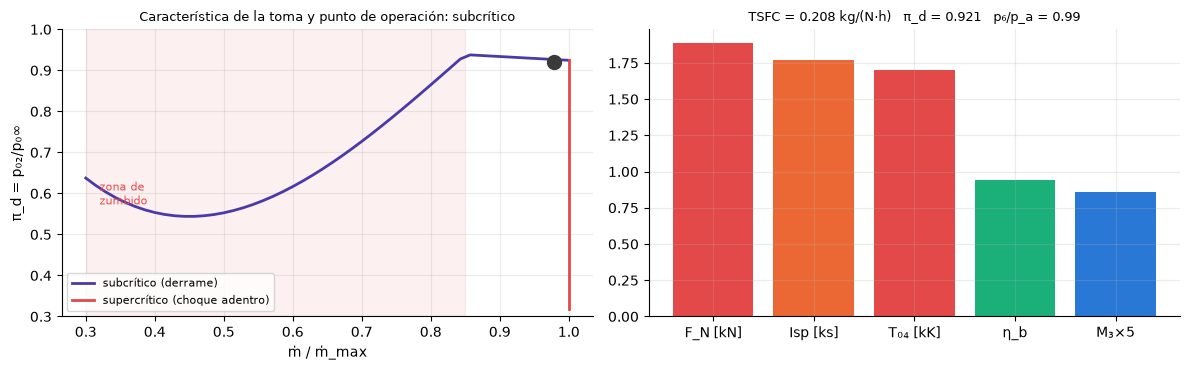

In [31]:
def widget_caracteristica(Minf=2.0, comb="Jet A-1 (n-heptano)", phi=0.6, geometria="corregida"):
    G = GEO if geometria == "corregida" else GEO_E
    o = punto(Minf, 10000.0, comb, phi, G)
    if not o["ok"]:
        print("Sin punto de operación:", o["regimen"]); return
    tm = toma(Minf, G); pic = tm["p0_cono"]*choque_normal(tm["Mc"])["p0r"]
    mrs = np.linspace(0.3, 1.0, 50)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
    a1.plot(mrs, [pic*caracteristica_toma(m) for m in mrs], color=COL["choque"], lw=2, label="subcrítico (derrame)")
    zs = np.linspace(tm["Mc"], 3.0, 30)
    a1.plot([1.0]*len(zs), [tm["p0_cono"]*choque_normal(M)["p0r"] for M in zs], color=COL["gas"], lw=2, label="supercrítico (choque adentro)")
    a1.axvspan(0.3, GEO["m_buzz"], color=COL["aviso"], alpha=0.08); a1.text(0.32, pic*0.62, "zona de\nzumbido", color=COL["aviso"], fontsize=8)
    a1.plot(o["mr"], o["pi_d"], "o", color=COL["tinta"], ms=10)
    a1.set_xlabel("ṁ / ṁ_max"); a1.set_ylabel("π_d = p₀₂/p₀∞"); a1.set_ylim(0.3, 1.0); a1.legend(fontsize=8, loc="lower left")
    a1.set_title("Característica de la toma y punto de operación: %s" % o["regimen"], fontsize=9)
    nombres = ["F_N [kN]", "Isp [ks]", "T₀₄ [kK]", "η_b", "M₃×5"]
    vals = [o["Fn"]/1e3, o["Isp"]/1e3, o["T04"]/1e3, o["eta_b"], 5*o["M3"]]
    a2.bar(nombres, vals, color=[COLC.get(comb, COL["gas"]), COL["tibio"], COL["gas"], COL["verde"], COL["aire"]])
    a2.set_title("TSFC = %.3f kg/(N·h)   π_d = %.3f   p₆/p_a = %.2f" % (o["TSFC"], o["pi_d"], o["p6"]/o["p"]), fontsize=9)
    plt.tight_layout(); plt.show()
w2 = dict(Minf=FloatSlider(value=2.0, min=1.8, max=3.2, step=0.1, description="M∞", continuous_update=False),
          comb=Dropdown(options=list(COMBUSTIBLES), value="Jet A-1 (n-heptano)", description="combustible"),
          phi=FloatSlider(value=0.6, min=0.3, max=1.0, step=0.05, description="φ", continuous_update=False),
          geometria=ToggleButtons(options=["corregida", "garganta de la entrega"], description="geometría"))
display(VBox([HBox([w2["Minf"], w2["phi"]]), HBox([w2["comb"], w2["geometria"]]), interactive_output(widget_caracteristica, w2)]))

## 9. Desempeño en vuelo y comparación con la tesis de Dallos

El mapa del motor de geometría fija se calcula en Mach y riqueza para cada combustible, a 10 km (en caché). Muestra lo que un análisis de ciclo ideal oculta:
- a Mach bajo el aire está demasiado frío y la llama se apaga;
- a Mach alto la toma de un solo cono pierde recuperación;
- la garganta fija confina la riqueza útil entre el régimen supercrítico y el zumbido.

**V4. Contra la tesis de Dallos (2024).** Dallos analiza un ciclo ideal, con toma crítica y garganta y salida adaptadas, usando su propio $f(M)$. Para compararlo se usa el modo `ciclo=True` del modelo, que impone esas mismas condiciones, con el $f(M)$ leído de su figura.

mapas listos (0 s)


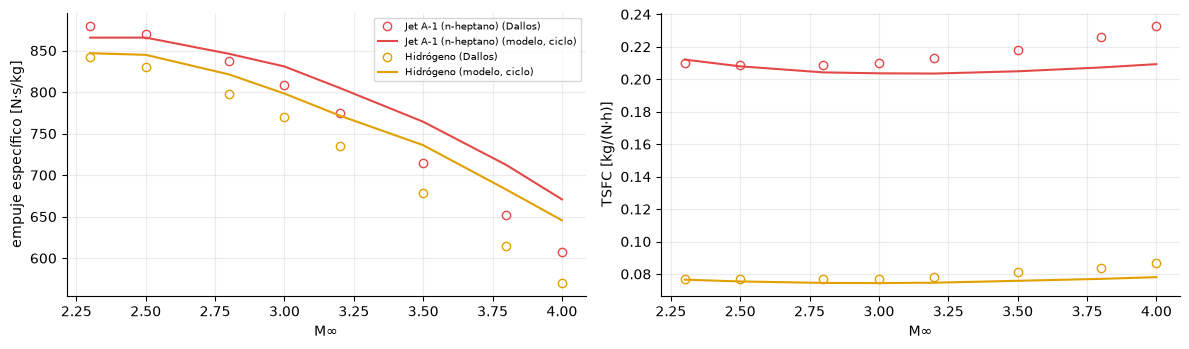

,combustible,M,F esp Dallos,F esp modelo,TSFC Dallos,TSFC modelo,π_d modelo,err F [%],err TSFC [%]
0,Jet A-1 (n-heptano),2.3,880,865.570,0.210,0.212,0.833,-1.640,1.007
1,Jet A-1 (n-heptano),2.5,870,865.646,0.209,0.208,0.765,-0.500,-0.509
2,Jet A-1 (n-heptano),2.8,838,846.144,0.209,0.204,0.659,0.972,-2.287
3,Jet A-1 (n-heptano),3.0,808,830.857,0.210,0.204,0.591,2.829,-3.026
4,Jet A-1 (n-heptano),3.2,775,804.898,0.213,0.204,0.526,3.858,-4.458
5,Jet A-1 (n-heptano),3.5,715,764.313,0.218,0.205,0.439,6.897,-6.014
6,Jet A-1 (n-heptano),3.8,652,712.178,0.226,0.207,0.364,9.230,-8.296
7,Jet A-1 (n-heptano),4.0,607,670.836,0.233,0.209,0.321,10.517,-10.176
8,Hidrógeno,2.3,842,846.849,0.077,0.077,0.833,0.576,-0.625
9,Hidrógeno,2.5,830,844.891,0.077,0.075,0.765,1.794,-2.054


In [33]:
Ms_map = [1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2]
phis_map = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
t0 = time.time()
MAPAS = {c: correr("mapa_" + c, lambda c=c: mapa_motor(c, 10000.0, Ms_map, phis_map)) for c in COMBUSTIBLES}
print("mapas listos (%.0f s)" % (time.time() - t0))
# Dallos (lectura de su figura): f(M), empuje especifico [N s/kg] y TSFC [kg/(N h)]
DALLOS = {"Jet A-1 (n-heptano)": dict(M=[2.3, 2.5, 2.8, 3.0, 3.2, 3.5, 3.8, 4.0], f=[0.051, 0.050, 0.048, 0.047, 0.0455, 0.0435, 0.041, 0.039],
                                      Fe=[880, 870, 838, 808, 775, 715, 652, 607], TSFC=[0.210, 0.209, 0.209, 0.210, 0.213, 0.218, 0.226, 0.233]),
          "Hidrógeno": dict(M=[2.3, 2.5, 2.8, 3.0, 3.2, 3.5, 3.8, 4.0], f=[0.018, 0.0177, 0.0170, 0.0165, 0.016, 0.0155, 0.0146, 0.014],
                            Fe=[842, 830, 798, 770, 735, 678, 615, 570], TSFC=[0.077, 0.077, 0.077, 0.077, 0.078, 0.081, 0.084, 0.087])}
def comparar_dallos():
    out = {}
    for c, d in DALLOS.items():
        fst = mezcla(c, 1.0, 400.0, 1e5)[2]
        res = [punto(M, 10000.0, c, f/fst, ciclo=True) for M, f in zip(d["M"], d["f"])]
        out[c] = dict(Fe=[r["F_esp"] for r in res], TSFC=[r["TSFC"] for r in res], pi=[r["pi_d"] for r in res])
    return out
DAL = correr("dallos", comparar_dallos)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
filas = []
for c, d in DALLOS.items():
    axs[0].plot(d["M"], d["Fe"], "o", color=COLC[c], mfc="none", label=c + " (Dallos)")
    axs[0].plot(d["M"], DAL[c]["Fe"], "-", color=COLC[c], label=c + " (modelo, ciclo)")
    axs[1].plot(d["M"], d["TSFC"], "o", color=COLC[c], mfc="none"); axs[1].plot(d["M"], DAL[c]["TSFC"], "-", color=COLC[c])
    for k, M in enumerate(d["M"]):
        filas.append((c, M, d["Fe"][k], DAL[c]["Fe"][k], d["TSFC"][k], DAL[c]["TSFC"][k], DAL[c]["pi"][k]))
axs[0].set_xlabel("M∞"); axs[0].set_ylabel("empuje específico [N·s/kg]"); axs[0].legend(fontsize=7)
axs[1].set_xlabel("M∞"); axs[1].set_ylabel("TSFC [kg/(N·h)]")
plt.tight_layout(); plt.show()
V4 = pd.DataFrame(filas, columns=["combustible", "M", "F esp Dallos", "F esp modelo", "TSFC Dallos", "TSFC modelo", "π_d modelo"])
V4["err F [%]"] = 100*(V4["F esp modelo"]/V4["F esp Dallos"] - 1); V4["err TSFC [%]"] = 100*(V4["TSFC modelo"]/V4["TSFC Dallos"] - 1)
display(V4.round(3))

El acuerdo es bueno entre Mach 2.3 y 2.8 (≤ 3.3 % en empuje específico y TSFC). Por encima, el modelo da **más** empuje específico que la tesis (+11 % con Jet A-1 y +13 % con hidrógeno a Mach 4) y su TSFC deja de crecer, aunque su toma de un solo cono recupera menos presión total ($\pi_d$ = 0.32 a Mach 4). Las dos diferencias apuntan a cómo se trata el gas caliente: aquí la tobera expande productos reales (Cantera, composición congelada) desde un $T_{04}$ de equilibrio. Las hipótesis de propiedades de la tesis a Mach alto no están documentadas en la figura, así que la brecha **no se atribuye a una causa única** y queda como pregunta abierta (ejercicio 5). A Mach 3–4 los ramjets reales usan, además, tomas de dos o tres conos o de compresión mixta (ejercicio 2).

**Widget 5: tablero de operación.** Elige el Mach de vuelo, la altitud, el combustible y la riqueza. El tablero resuelve el acople completo (1–5 s por punto) y muestra el régimen, las estaciones y el desempeño.

HTML(value="<div style='padding:6px;border-radius:4px;background:#1baf7a;color:white;font-weight:bold'>Régimen…

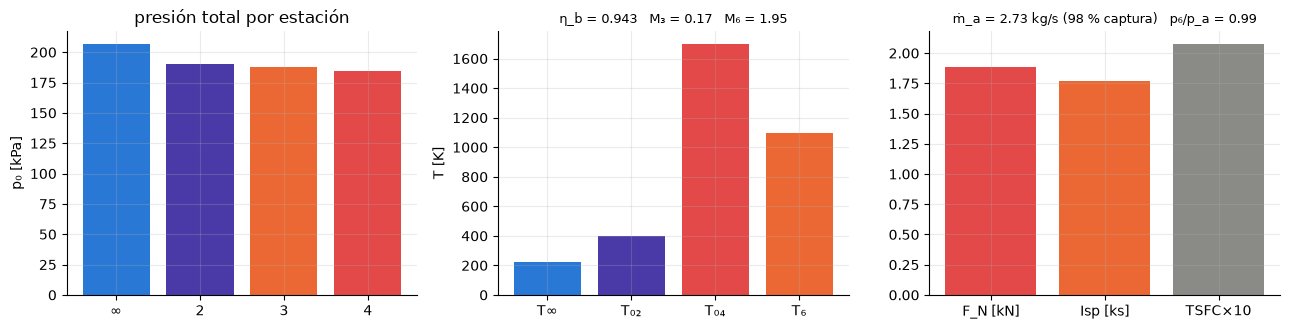

F_N = 1887 N | Isp = 1768 s | TSFC = 0.208 kg/(N·h) | arrastre aditivo 21 N | τ_res/τ_apagado = 3.9 | (0.6 s)


In [35]:
def widget_tablero(Minf=2.0, h=10000.0, comb="Jet A-1 (n-heptano)", phi=0.6):
    t0 = time.time(); o = punto(Minf, h, comb, phi, detalle=True)
    if not o["ok"]:
        display(HTML("<b style='color:#e34948'>%s</b>" % o["regimen"])); return
    color = "#1baf7a" if o["regimen"] in ("supercrítico", "crítico", "subcrítico") else "#e34948"
    display(HTML("<div style='padding:6px;border-radius:4px;background:%s;color:white;font-weight:bold'>Régimen: %s</div>" % (color, o["regimen"])))
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
    est = ["∞", "2", "3", "4", "6"]
    p0s = [o["p0"], o["p02"], o["p03"], o["p04"], np.nan]
    axs[0].bar(est[:4], np.array(p0s[:4])/1e3, color=[COL["aire"], COL["choque"], COL["tibio"], COL["gas"]])
    axs[0].set_ylabel("p₀ [kPa]"); axs[0].set_title("presión total por estación")
    axs[1].bar(["T∞", "T₀₂", "T₀₄", "T₆"], [o["T"], o["T0"], o["T04"], o["T6"]], color=[COL["aire"], COL["choque"], COL["gas"], COL["tibio"]])
    axs[1].set_ylabel("T [K]"); axs[1].set_title("η_b = %.3f   M₃ = %.2f   M₆ = %.2f" % (o["eta_b"], o["M3"], o["M6"]), fontsize=9)
    axs[2].bar(["F_N [kN]", "Isp [ks]", "TSFC×10"], [o["Fn"]/1e3, o["Isp"]/1e3, 10*o["TSFC"]], color=[COLC[comb], COL["tibio"], COL["gris"]])
    axs[2].set_title("ṁ_a = %.2f kg/s (%.0f %% captura)   p₆/p_a = %.2f" % (o["ma"], 100*o["mr"], o["p6"]/o["p"]), fontsize=9)
    plt.tight_layout(); plt.show()
    print("F_N = %.0f N | Isp = %.0f s | TSFC = %.3f kg/(N·h) | arrastre aditivo %.0f N | τ_res/τ_apagado = %.1f | (%.1f s)" %
          (o["Fn"], o["Isp"], o["TSFC"], o["D_add"], o["tau_res"]/max(o["tau_bo"], 1e-9), time.time() - t0))
w5 = dict(Minf=FloatSlider(value=2.0, min=1.6, max=3.4, step=0.1, description="M∞", continuous_update=False),
          h=FloatSlider(value=10000, min=0, max=20000, step=1000, description="h [m]", continuous_update=False),
          comb=Dropdown(options=list(COMBUSTIBLES), value="Jet A-1 (n-heptano)", description="combustible"),
          phi=FloatSlider(value=0.6, min=0.3, max=1.0, step=0.05, description="φ", continuous_update=False))
display(VBox([HBox([w5["Minf"], w5["h"]]), HBox([w5["comb"], w5["phi"]]), interactive_output(widget_tablero, w5)]))

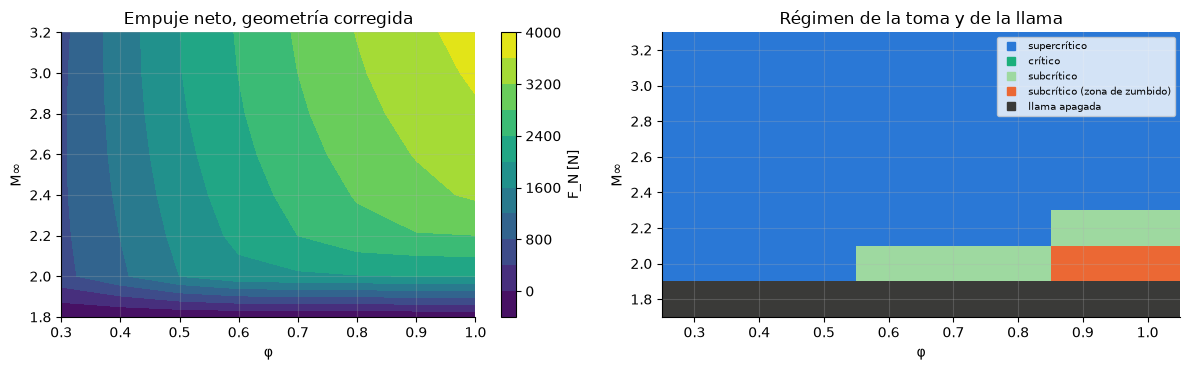

In [36]:
# Mapa de operación de la geometría fija (Jet A-1, 10 km): empuje y régimen
mp = MAPAS["Jet A-1 (n-heptano)"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
cs = a1.contourf(mp["phi"], mp["M"], mp["F"], levels=12, cmap="viridis"); plt.colorbar(cs, ax=a1, label="F_N [N]")
codigo = {"supercrítico": 0, "crítico": 1, "subcrítico": 2, "subcrítico (zona de zumbido)": 3, "llama apagada": 4}
Z = np.array([[codigo.get(r, 5) for r in fila] for fila in mp["reg"]], dtype=float)
a2.imshow(Z, origin="lower", aspect="auto", extent=[mp["phi"][0] - 0.05, mp["phi"][-1] + 0.05, mp["M"][0] - 0.1, mp["M"][-1] + 0.1],
          cmap=plt.matplotlib.colors.ListedColormap(["#2a78d6", "#1baf7a", "#9ed9a0", "#eb6834", "#3a3a38", "#e34948"]), vmin=-0.5, vmax=5.5)
for k, v in codigo.items():
    a2.plot([], [], "s", color=["#2a78d6", "#1baf7a", "#9ed9a0", "#eb6834", "#3a3a38"][v], label=k)
a2.legend(fontsize=7, loc="upper right"); a2.set_xlabel("φ"); a2.set_ylabel("M∞"); a1.set_xlabel("φ"); a1.set_ylabel("M∞")
a1.set_title("Empuje neto, geometría corregida"); a2.set_title("Régimen de la toma y de la llama")
plt.tight_layout(); plt.show()

## 10. Dinámica: el zumbido de la toma (*buzz*)

Si la cámara exige más presión de la que la toma puede dar (mucho combustible, o una garganta pequeña), el choque normal sale del labio y el motor derrama aire. Por debajo de un caudal crítico (~85 % de la captura, **SUPUESTO** a partir de los ensayos NACA), la característica de la toma tiene **pendiente positiva**. El sistema se vuelve entonces inestable, igual que un compresor en oleada. El choque oscila de forma violenta entre el cono y el labio, a decenas o cientos de hertz.

Se usa el modelo de Greitzer adaptado. La columna de aire del difusor actúa como la inercia, la cámara como el resorte (capacitancia) y la garganta sónica como la descarga:

$$\frac{L_d\,\dot m_{max}}{A_d\,p_{0\infty}}\frac{d\tilde m}{dt}=\pi_c\,\Pi(\tilde m)-\tilde P,\qquad
\frac{V_c\,p_{0\infty}}{R\,T_{04}\,\dot m_{max}}\frac{d\tilde P}{dt}=\tilde m(1+f)-k_n\frac{\tilde P}{\sqrt{\tilde T}},\qquad
\tau_c\frac{d\tilde T}{dt}=\tilde T_{obj}(t)-\tilde T$$

El parámetro de estabilidad es $B=\frac{U}{2\omega_H L_d}$, con $\omega_H$ la frecuencia de Helmholtz. Si $B$ es pequeño, un exceso de combustible solo desplaza el punto de operación. Si es grande, el sistema entra en un **ciclo límite**. El widget aplica un escalón de combustible (que sube $T_{04}$) en $t=20$ ms.

In [38]:
# === Modelo dinámico de zumbido tipo Greitzer (toma + cámara + garganta sónica) ===
def zumbido(op, Tc_rel, t_fin=0.3, L_d=0.55, A_d=0.018, V_c=0.0127, mb=0.85, tau_c=0.004):
    """Modelo dinamico tipo Greitzer toma + camara (variables adimensionales):
       inercia de la columna del difusor:  (L_d m_max/(A_d p0)) dm/dt = pi_c*Pi(m) - P
       llenado de la camara:               (V_c p0/(R T_c m_max)) dP/dt = m (1+f) - k_n P sqrt(T_ref/T_c)
       combustion con retardo:             dT/dt = (T_obj(t) - T)/tau_c
    El caudal de la tobera ~ p/sqrt(T) (garganta sonica); k_n se fija con el punto estacionario op."""
    m_max, p0, pi_c0, T_ref = op["m_max"], op["p0"], op["pi_d"], op["T04"]
    pi_c = pi_c0/caracteristica_toma(op["mr"], mb)         # la caracteristica pasa por el punto calculado
    m0 = op["mr"]; P0 = pi_c*caracteristica_toma(m0, mb)
    k_n = m0*(1 + op["f"])/P0
    Rg = 287.0
    def rhs(t, y):
        m, P, Tr = y
        dm = A_d*p0/(L_d*m_max)*(pi_c*caracteristica_toma(m, mb) - P)
        dP = Rg*T_ref*Tr*m_max/(V_c*p0)*(m*(1 + op["f"]) - k_n*P/math.sqrt(max(Tr, 0.2)))
        dT = (Tc_rel(t) - Tr)/tau_c
        return [dm, dP, dT]
    s = solve_ivp(rhs, [0, t_fin], [m0, P0, 1.0], method="LSODA", max_step=1e-4, rtol=1e-7, atol=1e-9)
    f_H = math.sqrt(A_d*Rg*T_ref*1.3/(L_d*V_c))/(2*math.pi)     # frecuencia de Helmholtz (referencia)
    return s, f_H

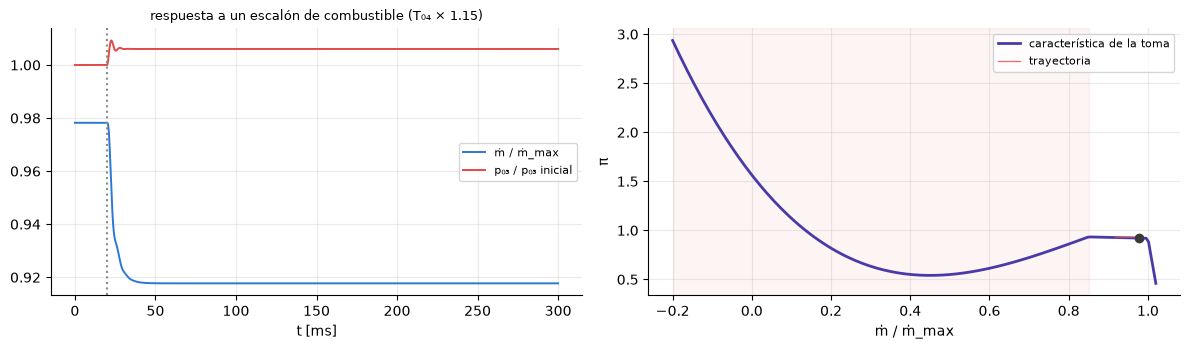

Estable: nuevo punto ṁ/ṁ_max = 0.918 (oscilación residual ±0.0000). Helmholtz 203 Hz


In [39]:
OP_Z = punto(2.0, 10000.0, "Jet A-1 (n-heptano)", 0.6)
def widget_zumbido(escalon=1.15, factor_V=1.0):
    Tc = lambda t: 1.0 if t < 0.02 else escalon
    s, fH = zumbido(OP_Z, Tc, t_fin=0.3, V_c=0.0127*factor_V)
    m, P = s.y[0], s.y[1]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
    a1.plot(1e3*s.t, m, color=COL["aire"], lw=1.4, label="ṁ / ṁ_max")
    a1.plot(1e3*s.t, P/OP_Z["pi_d"], color=COL["gas"], lw=1.4, label="p₀₃ / p₀₃ inicial")
    a1.axvline(20, color=COL["gris"], ls=":"); a1.set_xlabel("t [ms]"); a1.legend(fontsize=8)
    a1.set_title("respuesta a un escalón de combustible (T₀₄ × %.2f)" % escalon, fontsize=9)
    mrs = np.linspace(-0.2, 1.02, 200); pic = OP_Z["pi_d"]/caracteristica_toma(OP_Z["mr"])
    a2.plot(mrs, [pic*caracteristica_toma(x) for x in mrs], color=COL["choque"], lw=2, label="característica de la toma")
    a2.plot(m, P, color=COL["gas"], lw=0.9, alpha=0.8, label="trayectoria")
    a2.plot(m[0], P[0], "o", color=COL["tinta"]); a2.axvspan(-0.2, 0.85, color=COL["aviso"], alpha=0.06)
    a2.set_xlabel("ṁ / ṁ_max"); a2.set_ylabel("π"); a2.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    cola = s.t > 0.15
    amp = (m[cola].max() - m[cola].min())/2
    if amp > 0.05:
        cruces = np.where(np.diff(np.sign(m[cola] - m[cola].mean())) > 0)[0]
        f = (len(cruces) - 1)/(s.t[cola][cruces[-1]] - s.t[cola][cruces[0]]) if len(cruces) > 2 else np.nan
        print("ZUMBIDO: ciclo límite de amplitud ±%.2f en caudal, f ≈ %.0f Hz (Helmholtz de referencia %.0f Hz)" % (amp, f, fH))
    else:
        print("Estable: nuevo punto ṁ/ṁ_max = %.3f (oscilación residual ±%.4f). Helmholtz %.0f Hz" % (m[-1], amp, fH))
w6 = dict(escalon=FloatSlider(value=1.15, min=1.0, max=1.5, step=0.01, description="T₀₄ × ", continuous_update=False),
          factor_V=FloatSlider(value=1.0, min=0.5, max=15.0, step=0.5, description="V cámara ×", continuous_update=False))
display(VBox([HBox(list(w6.values())), interactive_output(widget_zumbido, w6)]))

Una cámara pequeña (B bajo) absorbe el escalón: el choque sale un poco y se estabiliza. Si se multiplica el volumen de la cámara (o la longitud de la cámara de aire aguas abajo), el mismo escalón dispara un ciclo límite de decenas de hertz. Este es el zumbido que destruyó varias tomas en los ensayos de los años 50, y por eso el control de combustible de un ramjet limita $\phi$ según el margen de la toma.

## 11. Misión: un blanco aéreo supersónico

**SUPUESTO de vehículo:** blanco aéreo de 130 kg al despegue (95 kg en seco y 35 kg de combustible), con área de referencia de 0.070 m² (cuerpo de 0.30 m de diámetro) y $C_D=0.14+0.18/\sqrt{M^2-1}$. Un acelerador lo deja a Mach 2 a 10 km. El ramjet usa el mapa de la §9 (interpolado) y un controlador PI ajusta $\phi$ para sostener el Mach objetivo:

$$(m_{seco}+m_c)\frac{dV}{dt}=F_N(M,\phi)-D(M),\qquad \frac{dm_c}{dt}=-\dot m_f(M,\phi),\qquad \phi=\phi_0+K_p(M_{obj}-M)+K_i\!\int(M_{obj}-M)\,dt$$

In [42]:
# === Vehículo, mapa del motor y trayectoria con control PI de combustible ===
from scipy.interpolate import RegularGridInterpolator
VEH = dict(m_seco=95.0, m_comb=35.0, S_ref=0.070, h=10000.0)

def arrastre(M, h, S_ref):
    """SUPUESTO: vehiculo esbelto (blanco aereo); C_D supersonico simple = friccion + onda ~ 1/sqrt(M^2-1)."""
    CD = 0.14 + 0.18/math.sqrt(max(M**2 - 1, 0.05)) if M > 1.05 else 0.30
    T, p, rho = isa(h)
    V = M*math.sqrt(1.4*R_AIRE*T)
    return 0.5*rho*V**2*S_ref*CD

def trayectoria(mapa, M0, M_obj, veh=VEH, t_fin=300.0, Kp=1.5, Ki=0.6, phi_min=0.35, phi_max=1.0):
    """Vuelo nivelado tras el acelerador: m dV/dt = F(M, phi) - D(M), dm/dt = -mf; un PI ajusta phi para
    sostener el Mach objetivo (como el control de combustible de un misil o blanco aereo)."""
    Fi = RegularGridInterpolator((mapa["M"], mapa["phi"]), np.nan_to_num(mapa["F"], nan=-500.0), bounds_error=False, fill_value=None)
    Mi = RegularGridInterpolator((mapa["M"], mapa["phi"]), np.nan_to_num(mapa["mf"], nan=0.0), bounds_error=False, fill_value=None)
    T, p, rho = isa(veh["h"]); a = math.sqrt(1.4*R_AIRE*T)
    def phi_de(M, I):
        return min(max(0.6 + Kp*(M_obj - M) + I, phi_min), phi_max)
    def rhs(t, y):
        V, mc, x, I = y
        M = V/a
        if mc <= 0:
            F, mf, ph = 0.0, 0.0, 0.0
        else:
            ph = phi_de(M, I); F = float(Fi([[M, ph]])[0]); mf = float(Mi([[M, ph]])[0])
        D = arrastre(M, veh["h"], veh["S_ref"])
        dI = Ki*(M_obj - M) if (mc > 0 and phi_min < 0.6 + Kp*(M_obj - M) + I < phi_max) else 0.0
        return [(F - D)/(veh["m_seco"] + max(mc, 0.0)), -mf, V, dI]
    ev = lambda t, y: y[1]
    ev.terminal = False
    s = solve_ivp(rhs, [0, t_fin], [M0*a, veh["m_comb"], 0.0, 0.0], max_step=0.5, rtol=1e-6, atol=1e-6)
    M = s.y[0]/a
    ph = np.array([phi_de(Mk, Ik) if mc > 0 else 0.0 for Mk, Ik, mc in zip(M, s.y[3], s.y[1])])
    F = np.array([float(Fi([[Mk, pk]])[0]) if pk > 0 else 0.0 for Mk, pk in zip(M, ph)])
    D = np.array([arrastre(Mk, veh["h"], veh["S_ref"]) for Mk in M])
    return dict(t=s.t, M=M, phi=ph, F=F, D=D, comb=s.y[1], x=s.y[2])

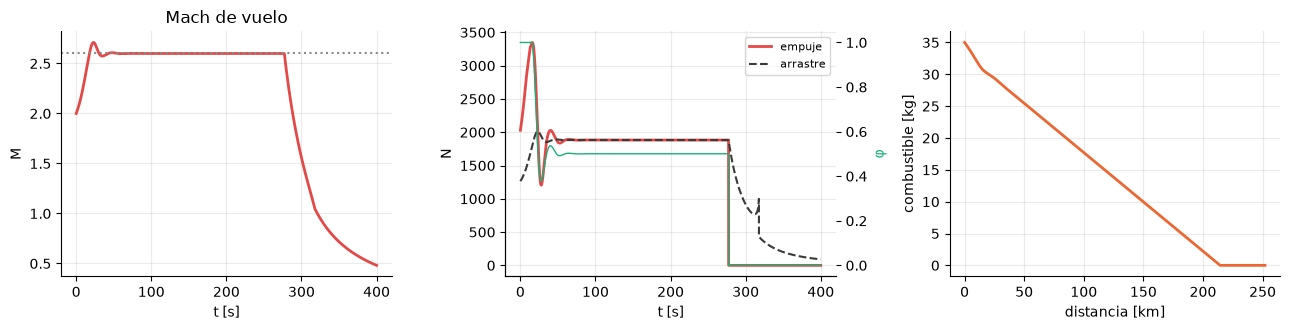

Alcance motorizado 214 km en 277 s  (Mach final 2.60; combustible agotado)


In [43]:
def widget_mision(comb="Jet A-1 (n-heptano)", M_obj=2.6, m_comb=35.0):
    veh = dict(VEH); veh["m_comb"] = m_comb
    tr = trayectoria(MAPAS[comb], 2.0, M_obj, veh, t_fin=400.0)
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
    axs[0].plot(tr["t"], tr["M"], color=COLC[comb], lw=2); axs[0].axhline(M_obj, color=COL["gris"], ls=":")
    axs[0].set_xlabel("t [s]"); axs[0].set_ylabel("M"); axs[0].set_title("Mach de vuelo")
    axs[1].plot(tr["t"], tr["F"], color=COLC[comb], lw=2, label="empuje"); axs[1].plot(tr["t"], tr["D"], color=COL["tinta"], ls="--", label="arrastre")
    axs[1].set_xlabel("t [s]"); axs[1].set_ylabel("N"); axs[1].legend(fontsize=8)
    ax2 = axs[1].twinx(); ax2.plot(tr["t"], tr["phi"], color=COL["verde"], lw=1); ax2.set_ylabel("φ", color=COL["verde"]); ax2.grid(False)
    axs[2].plot(tr["x"]/1e3, tr["comb"], color=COL["tibio"], lw=2); axs[2].set_xlabel("distancia [km]"); axs[2].set_ylabel("combustible [kg]")
    plt.tight_layout(); plt.show()
    agot = np.where(tr["comb"] <= 0)[0]
    t_q = tr["t"][agot[0]] if len(agot) else tr["t"][-1]
    x_q = tr["x"][agot[0]] if len(agot) else tr["x"][-1]
    print("Alcance motorizado %.0f km en %.0f s  (Mach final %.2f; %s)" % (x_q/1e3, t_q, tr["M"][agot[0] if len(agot) else -1],
          "combustible agotado" if len(agot) else "aún con combustible"))
w7 = dict(comb=Dropdown(options=list(COMBUSTIBLES), value="Jet A-1 (n-heptano)", description="combustible"),
          M_obj=FloatSlider(value=2.6, min=2.0, max=3.1, step=0.05, description="M objetivo", continuous_update=False),
          m_comb=FloatSlider(value=35.0, min=10.0, max=60.0, step=1.0, description="combustible [kg]", continuous_update=False))
display(VBox([HBox(list(w7.values())), interactive_output(widget_mision, w7)]))

In [44]:
# Alcance por combustible con la misma masa a bordo (35 kg) y Mach objetivo 2.6
filas = []
for c in COMBUSTIBLES:
    tr = trayectoria(MAPAS[c], 2.0, 2.6, VEH, t_fin=1500.0)
    agot = np.where(tr["comb"] <= 0)[0]; k = agot[0] if len(agot) else -1
    filas.append((c, tr["x"][k]/1e3, tr["t"][k], "sí" if len(agot) else "no (fin de la simulación)", np.nanmean(MAPAS[c]["Isp"][4])))
display(pd.DataFrame(filas, columns=["combustible", "alcance [km]", "tiempo [s]", "combustible agotado", "Isp medio a M=2.6 [s]"]).round(1))

,combustible,alcance [km],tiempo [s],combustible agotado,Isp medio a M=2.6 [s]
0,Hidrógeno,621.8,800.2,sí,4205.3
1,Metano,246.4,318.5,sí,1681.3
2,Jet A-1 (n-heptano),214.3,277.2,sí,1471.7
3,Octano (iso-octano),212.9,275.5,sí,1462.5


El hidrógeno da 2–3 veces más impulso específico, pero en un vehículo real el tanque limita el **volumen**, no la masa. Con 35 kg de H₂ líquido harían falta ~490 L, contra ~45 L de queroseno. Por eso los ramjets operativos queman combustibles líquidos densos, y el hidrógeno se reserva para scramjets de investigación (ejercicio 4).

## 12. 🎓 Hallazgos sobre la entrega de los estudiantes

| # | Hallazgo | Efecto | Cómo se trata aquí |
|---|---|---|---|
| 1 | El área de captura de su geometría Hermite (labio a 30.7 mm) es ~26 % de la que exige su propio caudal | el caudal de la tabla no puede entrar por la toma dibujada | toma rediseñada: choque en el labio a Mach 2 (§4) |
| 2 | La garganta de la tabla del artículo (139.7 mm) no coincide con la del código (92 mm) | las cifras publicadas no son reproducibles a la vez | se reproduce el código (V2) y se redimensiona la garganta con el acople |
| 3 | El caudal se impone en la garganta sin verificar que la toma lo pueda entregar | no hay régimen supercrítico ni subcrítico; el zumbido es invisible | acople toma–tobera por la posición del choque (§4, §8) |
| 4 | $c_p$ y $\gamma$ constantes en la cámara | $T_{04}$ sobreestimada ~150 K | equilibrio químico con Cantera (§6) |
| 5 | $\phi\approx0.45$ premezclado está en el límite de inflamabilidad de los hidrocarburos | el PSR del estabilizador se apaga | estabilizadores en V con mezcla local más rica, tabla de apagado (§6) |
| 6 | La punta Hermite es roma | choque desprendido cerca de la punta | cono recto de 25° con solución de Taylor–Maccoll (§3) |
| 7 | $\eta_d=0.92$ | consistente con MIL-E-5007D (0.92 a Mach 2) | se conserva como referencia de V3 |

Ninguno de estos hallazgos resta mérito al trabajo. La entrega reúne el flujo cuasi-1D, la geometría y el desempeño en un solo código abierto, y eso hizo posible esta lección.

## 13. Verificación

Cada submodelo se contrasta con una solución analítica exacta o con la fuente. El criterio de la lección es un error menor a 1 %.

In [48]:
VER = []
VER.append(("Taylor-Maccoll vs NACA 1135 (cono 10°, M2)", V1[0][2], V1[0][3]))
VER.append(("Taylor-Maccoll vs NACA 1135 (cono 20°, M2)", V1[1][2], V1[1][3]))
VER.append(("Rayleigh: M al llegar a 0.9999 T0*", VER_1D.iloc[0, 2], VER_1D.iloc[0, 1]))
VER.append(("Fanno: 4cfL*/D restante", VER_1D.iloc[1, 2], VER_1D.iloc[1, 1]))
er = entrega_ramjet()
VER.append(("Réplica de la entrega: empuje neto [N]", 1719.4, er["Fn"]))
VER.append(("Réplica de la entrega: M6", 2.033, er["M6"]))
# Tobera de Cantera con aire puro (gas casi ideal a 300 K) vs capacidad analítica de la garganta
g = ct.Solution("air.yaml"); g.TP = 300.0, 2e5; Ya = g.Y
cp, cv = g.cp_mass, g.cv_mass; ga = cp/cv; Ra = cp - cv
gas_aire = ct.Solution("air.yaml")
def cap_aire(T0, p0, A):
    gas_aire.TP = T0, p0; s0, h0 = gas_aire.entropy_mass, gas_aire.enthalpy_mass
    G = lambda p: (gas_aire.__setattr__("SP", (s0, p)), gas_aire.density*math.sqrt(2*(h0 - gas_aire.enthalpy_mass)))[1]
    from scipy.optimize import minimize_scalar
    r = minimize_scalar(lambda p: -G(p), bounds=(0.4*p0, 0.7*p0), method="bounded", options=dict(xatol=1e-3))
    return -r.fun*A
VER.append(("Capacidad de garganta (aire 300 K): Cantera vs isentrópica analítica", flujo_masico_param(1.0, ga, Ra)*2e5*0.01/math.sqrt(300.0), cap_aire(300.0, 2e5, 0.01)))
# Conservación en el punto de diseño
o = punto(2.0, 10000.0, "Jet A-1 (n-heptano)", 0.6, detalle=True)
A6 = math.pi*GEO["r_s"]**2
VER.append(("Masa: ρ6 u6 A6 = ṁa(1+f) [kg/s]", o["mg"], o["salida"]["rho"]*o["salida"]["u"]*A6))
gq = sol("Jet A-1 (n-heptano)"); gq.TPY = o["T04"], o["p04"], o["prod"]["Y"]; h04 = gq.enthalpy_mass
gq.TPY = o["T6"], o["p6"], o["prod"]["Y"]
VER.append(("Energía: h04 = h6 + u6²/2 [kJ/kg]", h04/1e3, (gq.enthalpy_mass + 0.5*o["u6"]**2)/1e3))
VERIF = pd.DataFrame(VER, columns=["verificación", "referencia", "modelo"])
VERIF["error [%]"] = 100*(VERIF["modelo"]/VERIF["referencia"] - 1)
VERIF["< 1 %"] = np.where(VERIF["error [%]"].abs() < 1, "✓", "✗")
display(VERIF.round(5))
print("Todas las verificaciones con error < 1 %:", bool((VERIF["error [%]"].abs() < 1).all()))

,verificación,referencia,modelo,error [%],< 1 %
0,"Taylor-Maccoll vs NACA 1135 (cono 10°, M2)",31.20000,31.20609,0.01952,✓
1,"Taylor-Maccoll vs NACA 1135 (cono 20°, M2)",37.80000,37.79594,-0.01074,✓
2,Rayleigh: M al llegar a 0.9999 T0*,0.98809,0.98809,-0.00000,✓
3,Fanno: 4cfL*/D restante,1.05985,1.05985,-0.00000,✓
4,Réplica de la entrega: empuje neto [N],1719.40000,1722.26238,0.16648,✓
5,Réplica de la entrega: M6,2.03300,2.03125,-0.08603,✓
6,Capacidad de garganta (aire 300 K): Cantera vs...,4.66804,4.66988,0.03955,✓
7,Masa: ρ6 u6 A6 = ṁa(1+f) [kg/s],2.84354,2.84354,-0.00000,✓
8,Energía: h04 = h6 + u6²/2 [kJ/kg],29.30325,29.30325,0.00000,✓


Todas las verificaciones con error < 1 %: True


Las comparaciones con datos experimentales se presentan aparte, porque el modelo no pretende igualarlas al 1 %:
- **V3**, recuperación de la toma frente a MIL-E-5007D y NACA RM E52L18a;
- **V4**, tendencias del ciclo frente a Dallos.

El modelo omite efectos que el experimento sí tiene (interacción choque–capa límite, distorsión) y supone otros que la tesis también supone (toma crítica ideal). La diferencia se explica en cada caso.

## 14. Conclusión

| Concepto | Lo que muestra el modelo |
|---|---|
| Compresión por choques | Un cono de 25° más un choque normal recupera ~0.9 de la presión total a Mach 2; un pitot solo, 0.72 |
| Acople toma–tobera | La garganta fija el caudal. La posición del choque terminal se ajusta sola hasta que la toma entrega lo que la tobera traga |
| Estabilización de llama | Sin un estabilizador, la mezcla a 400 K no se enciende en la cámara; con él, el PSR fija un límite de apagado |
| Estrangulamiento térmico | Calentar un flujo subsónico lo acelera hacia M = 1; por eso la cámara trabaja a M ≈ 0.2 |
| Zumbido | La característica de la toma con pendiente positiva hace inestable el sistema, igual que la oleada de un compresor |
| Misión | El empuje cae con el Mach por la recuperación de la toma; el control de φ sostiene el vuelo hasta agotar el combustible |

## Ejercicios

1. **Rediseño del cono.** Con el widget 1, encuentra el semiángulo óptimo a Mach 2.5. Cambia `GEO["cono"]` y `GEO["M_dis"]`, y verifica con el widget 5 cuánto empuje gana el motor a ese Mach. ¿Qué pasa a Mach 2?
2. **Toma de dos conos.** Implementa un segundo choque oblicuo (cono doble, con `choque_oblicuo` para el segundo) antes del choque normal. Compara la recuperación con MIL-E-5007D a Mach 3 y repite la comparación con Dallos (V4).
3. **Margen de zumbido.** Para Jet A-1 a Mach 2, encuentra la riqueza máxima que mantiene $\dot m/\dot m_{max}>0.85$, con la garganta de la entrega y con la corregida. ¿Qué área de garganta maximiza el empuje sin entrar en zumbido?
4. **Hidrógeno en volumen.** Repite la tabla de alcance de la §11 fijando el **volumen** del tanque en 45 L (densidad del H₂ líquido 71 kg/m³ y del Jet A-1 800 kg/m³). ¿Qué combustible vuela más lejos?
5. **Expansión en equilibrio.** Cambia `modo="equilibrio"` en `punto` y cuantifica la ganancia de empuje a Mach 3 con φ = 1 para cada combustible. ¿Por qué es mayor con hidrógeno?

## Referencias

- Cadavid Franco, S. & Bayona Roa, C. *One-Dimensional Numerical Modelling of a Supersonic RAMJET Engine with Parametrizable Geometry* (manuscrito y códigos MATLAB, PUJ).
- Dallos Trujillo, A. & Bayona Roa, C. A. (2024). *Integrated Thermodynamic Analysis of a Generic RAMJET*, tesis de pregrado, Pontificia Universidad Javeriana.
- Ames Research Staff (1953). *Equations, Tables, and Charts for Compressible Flow*, NACA Report 1135.
- U.S. Department of Defense (1973). MIL-E-5007D, *Engines, Aircraft, Turbojet and Turbofan, General Specification for* (recuperación de la toma).
- NACA RM E52L18a (1953), recuperación de presión total de una toma de cono a Mach 2. NTRS 19930087580: https://ntrs.nasa.gov/api/citations/19930087580/downloads/19930087580.pdf
- Shapiro, A. H. (1953). *The Dynamics and Thermodynamics of Compressible Fluid Flow*, Vol. 1. Ronald Press.
- Greitzer, E. M. (1976). Surge and rotating stall in axial flow compressors, Part I. *J. Eng. Power* 98(2), 190–198.
- Metghalchi, M. & Keck, J. C. (1982). Burning velocities of mixtures of air with methanol, isooctane, and indolene at high pressure and temperature. *Combust. Flame* 48, 191–210.
- Goodwin, D. G. et al. (2023). *Cantera: An object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes*, v3.